# Relatório 05 — XGBoost: Otimização de Hiperparâmetros e Comparação com a Árvore de Decisão

**Projeto:** Previsão de evasão de clientes (churn) em 60 dias

**Etapa:** modelagem supervisionada, parte 2 (Miniprojeto 2 — PBL / CIn-UFPE)

**Entradas:** `data/processed/base_particionada.csv` (com o pré-processamento da Versão A) e `resultados/arvore_escolhida.json` (Relatório 04)

**Saída:** `resultados/xgboost_escolhido.json`

---

### Resumo

O Relatório 04 terminou com uma árvore de decisão interpretável, mas com dois limites claros: as suas probabilidades variam em degraus e a curva de aprendizado indicava que o modelo ainda deixava informação na mesa. Este relatório testa se um ***ensemble de árvores construído por gradient boosting***, o XGBoost, consegue extrair mais da mesma base e, sobretudo, ***se esse ganho compensa a perda de interpretabilidade***.

Para isso, o relatório percorre quatro etapas. Primeiro, mede o comportamento do XGBoost com os hiperparâmetros padrão e estuda o ***compromisso entre o número de árvores e a taxa de aprendizado***, que é o coração do boosting. Em seguida, compara os dois mecanismos de busca sugeridos no miniprojeto: a ***busca em grade*** (`GridSearchCV`), exaustiva, e a ***otimização bayesiana com Optuna***, que explora espaços contínuos e interrompe cedo as tentativas pouco promissoras. Depois, o modelo escolhido é avaliado no teste com as mesmas análises de sobreajuste do Relatório 04 e interpretado por três medidas de importância, incluindo os valores ***SHAP***, que o próprio XGBoost calcula. Por fim, a ***comparação direta com a árvore*** é feita no mesmo ponto de operação (recall-alvo de 80%), com intervalos de confiança por *bootstrap* para verificar se a diferença é real.

Todo o protocolo é idêntico ao do Relatório 04: as mesmas 5 dobras estratificadas, o mesmo pré-processamento reajustado dentro de cada dobra, a AUC-PR como critério de escolha do modelo e o recall-alvo para o limiar. Dessa forma, qualquer diferença entre os dois relatórios pode ser atribuída ao algoritmo, e não ao procedimento.

> **Como ler as saídas.** Além das explicações em texto, as células de análise terminam com um parágrafo de ***leitura dos resultados***, gerado a partir dos próprios números calculados. Assim, o relatório permanece correto mesmo que alguma versão de biblioteca altere levemente os resultados.

## 1. Introdução

### 1.1 Onde estamos no projeto

A árvore escolhida no Relatório 04 alcançou AUC-PR de 0,627 na validação cruzada e de 0,615 no teste e, no ponto de operação de 80% de recall, acionava cerca de metade dos clientes. Além disso, revelou um perfil de risco claro: contrato mensal, cliente recente e sinais de atrito. O que ela não consegue fazer bem, porém, é combinar muitos sinais fracos ao mesmo tempo, porque cada folha precisa de pelo menos 40 clientes e, com isso, a árvore tem no máximo algumas dezenas de "perfis". O boosting ataca exatamente essa limitação.

### 1.2 Como o boosting aprende

Enquanto uma árvore de decisão tenta resolver o problema inteiro de uma só vez, o ***boosting*** constrói uma sequência de árvores pequenas (os chamados *weak learners*), em que **cada nova árvore corrige os erros das anteriores**. A previsão final é a soma das contribuições de todas elas:

$$\hat{y}_i = \sum_{k=1}^{K} \eta\, f_k(x_i)$$

em que $f_k$ é a $k$-ésima árvore e $\eta$ é a ***taxa de aprendizado*** (`learning_rate`). No ***gradient boosting***, a "correção" é feita de forma precisa: cada nova árvore é ajustada ao **gradiente** da função de perda (aqui, a *log-loss*), ou seja, à direção em que as previsões precisam se mover para reduzir o erro. Os clientes que o modelo atual classifica mal recebem, consequentemente, gradientes maiores e passam a atrair a atenção da próxima árvore.

O ***XGBoost*** (*eXtreme Gradient Boosting*) acrescenta a essa ideia uma função objetivo explicitamente **regularizada**:

$$\text{Obj} = \sum_{i} \ell(y_i, \hat{y}_i) + \sum_{k} \Omega(f_k), \qquad \Omega(f) = \gamma\,T + \tfrac{1}{2}\lambda \lVert w \rVert^2 + \alpha \lVert w \rVert_1$$

em que $T$ é o número de folhas da árvore e $w$ são os valores das folhas. Cada termo corresponde a um hiperparâmetro do miniprojeto: `gamma` ($\gamma$) é o ganho mínimo para que uma divisão valha a pena, funcionando como uma **poda** embutida; `reg_lambda` ($\lambda$) e `reg_alpha` ($\alpha$) encolhem os valores das folhas, impedindo que uma árvore isolada "grite" demais. Além disso, o XGBoost usa uma aproximação de segunda ordem da perda, o que torna cada árvore mais precisa, e oferece mecanismos de aleatoriedade inspirados nas florestas aleatórias: `subsample` sorteia uma fração dos clientes para cada árvore e `colsample_bytree` sorteia uma fração dos atributos. Ambos reduzem a correlação entre as árvores e, por isso, também atuam como regularização.

### 1.3 O compromisso entre número de árvores e taxa de aprendizado

A taxa de aprendizado $\eta$ controla o tamanho de cada passo de correção. Com $\eta$ grande, poucas árvores bastam para ajustar o treino, mas cada uma dá um passo largo e o modelo passa rapidamente do ponto, começando a ajustar ruído. Com $\eta$ pequeno, cada árvore corrige só um pouco; são necessárias, então, muito mais árvores, mas o caminho até o ótimo é mais suave e, em geral, o ponto final generaliza melhor. Por isso, `n_estimators` e `learning_rate` **não podem ser escolhidos separadamente**: o número ideal de árvores é aproximadamente inversamente proporcional à taxa de aprendizado. A Seção 4 mede esse compromisso diretamente.

### 1.4 Grade exaustiva × otimização bayesiana

O `GridSearchCV` testa **todas** as combinações de uma lista fixa de valores. É simples e reprodutível, mas o custo cresce de forma multiplicativa: com 8 hiperparâmetros e apenas 3 valores cada, seriam 6.561 combinações. Além disso, só testa os valores escolhidos de antemão, mesmo que o ótimo esteja entre eles.

O ***Optuna***, por outro lado, faz uma ***busca sequencial e adaptativa***. O seu amostrador padrão, o TPE (*Tree-structured Parzen Estimator*), separa as tentativas já feitas em "boas" e "ruins" e sorteia a próxima combinação onde a razão entre as duas densidades é maior, isto é, nas regiões que se pareceram com as melhores tentativas até agora. Como trabalha com distribuições, explora espaços **contínuos** (por exemplo, qualquer taxa de aprendizado entre 0,005 e 0,3, em escala logarítmica). Além disso, com um ***pruner***, ele interrompe uma tentativa no meio da validação cruzada quando o seu desempenho parcial já está abaixo da mediana das anteriores, economizando tempo para regiões mais promissoras.

### 1.5 Protocolo e roteiro

O protocolo é exatamente o do Relatório 04: escolha de hiperparâmetros pela **AUC-PR** média em 5 dobras estratificadas, pré-processamento reajustado dentro de cada dobra, limiar escolhido nas previsões fora da dobra para atingir **80% de recall** e teste usado uma única vez.

A **Seção 2** prepara o ambiente, os dados e a árvore de referência. A **Seção 3** avalia o XGBoost padrão. A **Seção 4** estuda o compromisso entre árvores e taxa de aprendizado. As **Seções 5 e 6** executam o GridSearchCV e o Optuna, e a **Seção 7** os compara e escolhe o modelo. A **Seção 8** define o limiar, a **Seção 9** avalia no teste e a **Seção 10** interpreta o modelo. Por fim, a **Seção 11** compara o XGBoost com a árvore, a **Seção 12** salva os resultados e a **Seção 13** conclui.

## 2. Ambiente, dados e árvore de referência

A célula de preparação é a mesma dos relatórios anteriores. No Colab, o `requirements.txt` instala o `optuna`, que não vem pré-instalado; o `xgboost`, por sua vez, já faz parte do ambiente padrão. Também definimos aqui duas pequenas funções de formatação, usadas nos parágrafos de leitura dos resultados.

In [1]:
# Setup: rode sempre primeiro
import os, sys

# No Colab: clona o repositório (só na primeira vez), entra na pasta, atualiza e instala as
# dependências. Localmente, a partir de notebooks/: sobe para a raiz, onde está o config.py.
if "google.colab" in sys.modules:
    if not os.path.exists("/content/previsao_de_evasao_de_clientes"):
        !git clone -q https://github.com/Gagdm/previsao_de_evasao_de_clientes.git /content/previsao_de_evasao_de_clientes
    %cd /content/previsao_de_evasao_de_clientes
    !git pull -q
    !pip install -q -r requirements.txt
elif os.path.basename(os.getcwd()) == "notebooks":
    %cd ..

import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import xgboost as xgb
from IPython.display import Markdown, display
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score, fbeta_score,
                             make_scorer, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate,
                                     learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

import config
from preprocessing import COLUNAS_ENTRADA, PreprocessadorChurn, variavel_de_origem

sns.set_theme(style="whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)
print(f"xgboost {xgb.__version__} | optuna {optuna.__version__}")

def br(x, casas=3):
    # Número no formato brasileiro (vírgula decimal).
    return f"{x:.{casas}f}".replace(".", ",")

def pct(x, casas=1):
    return f"{100 * x:.{casas}f}%".replace(".", ",")

def num(x):
    # Número "curto" (até 4 algarismos significativos), com vírgula decimal.
    return f"{x:.4g}".replace(".", ",")

def lista(itens):
    # ["a", "b", "c"] -> "a, b e c"
    itens = list(itens)
    return itens[0] if len(itens) == 1 else ", ".join(itens[:-1]) + " e " + itens[-1]

def leitura(texto, titulo="Leitura dos resultados."):
    # Parágrafo de interpretação gerado a partir dos números calculados na célula.
    display(Markdown(f"**{titulo}** " + texto))

/content/previsao_de_evasao_de_clientes
xgboost 3.4.1 | optuna 5.1.0


Os dados e o pré-processamento são os mesmos do Relatório 04. Repetimos, por segurança, a verificação de que o `PreprocessadorChurn`, ajustado no treino, reproduz exatamente a Versão A do MP1. Em seguida, carregamos os hiperparâmetros e o limiar da árvore escolhida, que serão usados como referência ao longo de todo o relatório.

In [2]:
base = pd.read_csv(config.BASE_PARTICIONADA)
treino = base[base["split"] == "treino"].reset_index(drop=True)
teste = base[base["split"] == "teste"].reset_index(drop=True)
X_treino, y_treino = treino[COLUNAS_ENTRADA], treino[config.ALVO]
X_teste, y_teste = teste[COLUNAS_ENTRADA], teste[config.ALVO]

preprocessador = PreprocessadorChurn().fit(X_treino)
versao_a = pd.read_csv(config.VERSAO_A).set_index(config.ID)
for nome, conjunto in [("treino", treino), ("teste", teste)]:
    gerado = preprocessador.transform(conjunto[COLUNAS_ENTRADA]).to_numpy(dtype=float)
    esperado = versao_a.loc[conjunto[config.ID], preprocessador.colunas_saida_].to_numpy(dtype=float)
    assert np.allclose(gerado, esperado), f"O pré-processamento não reproduz a Versão A no {nome}"
print(f"Treino: {len(X_treino)} | Teste: {len(X_teste)} | pré-processamento idêntico à Versão A")

# Árvore de referência (Relatório 04).
if not config.ARVORE_ESCOLHIDA.exists():
    raise FileNotFoundError("Rode o notebook 04 e salve resultados/arvore_escolhida.json no repositório antes deste.")
with open(config.ARVORE_ESCOLHIDA, encoding="utf-8") as arquivo:
    arvore_json = json.load(arquivo)
print(f"Árvore de referência: {arvore_json['estrategia']} | limiar {arvore_json['limiar']:.3f} | "
      f"AUC-PR validação {arvore_json['validacao_cruzada']['AUC_PR (validação)']:.3f}")

Treino: 3483 | Teste: 1493 | pré-processamento idêntico à Versão A
Árvore de referência: híbrida (pré + pós) | limiar 0.293 | AUC-PR validação 0.627


### 2.1 Protocolo comum

As funções abaixo repetem o protocolo do Relatório 04: as mesmas 5 dobras, as mesmas métricas e a mesma regra de limiar. A única novidade é a função `pipeline_xgb`, que acopla o XGBoost ao pré-processamento. Nela, fixamos `tree_method="hist"`, o algoritmo de construção de árvores mais rápido do XGBoost, e `random_state`, para que `subsample` e `colsample_bytree` sorteiem sempre os mesmos clientes e atributos.

In [3]:
dobras = StratifiedKFold(n_splits=config.N_DOBRAS, shuffle=True, random_state=config.RANDOM_STATE)
f2 = make_scorer(fbeta_score, beta=config.BETA)
METRICAS = {"AUC_PR": "average_precision", "AUC_ROC": "roc_auc", "recall": "recall",
            "precisao": make_scorer(precision_score, zero_division=0), "F2": f2, "acuracia": "accuracy"}

def pipeline_xgb(n_jobs=-1, **hiperparametros):
    modelo = xgb.XGBClassifier(tree_method="hist", eval_metric="logloss", random_state=config.RANDOM_STATE,
                               n_jobs=n_jobs, **hiperparametros)
    return Pipeline([("prep", PreprocessadorChurn()), ("modelo", modelo)])

def pipeline_arvore(**hiperparametros):
    return Pipeline([("prep", PreprocessadorChurn()),
                     ("modelo", DecisionTreeClassifier(random_state=config.RANDOM_STATE, **hiperparametros))])

def avaliar_cv(modelo, nome):
    inicio = time.time()
    r = cross_validate(modelo, X_treino, y_treino, cv=dobras, scoring=METRICAS, return_train_score=True)
    linha = {"modelo": nome}
    for m in METRICAS:
        linha[f"{m} (treino)"] = r[f"train_{m}"].mean()
        linha[f"{m} (validação)"] = r[f"test_{m}"].mean()
    linha["AUC_PR desvio (validação)"] = r["test_AUC_PR"].std()
    linha["tempo (s)"] = time.time() - inicio
    return linha

def limiar_para_recall(prob, y, alvo=config.RECALL_ALVO):
    # Maior limiar cujo recall (nas previsões fora da dobra) ainda atinge o alvo.
    for t in np.sort(np.unique(prob))[::-1]:
        if recall_score(y, prob >= t) >= alvo:
            return float(t)
    return float(np.min(prob))

def metricas(y, prob, limiar):
    previsto = (prob >= limiar).astype(int)
    return {"recall": recall_score(y, previsto), "precisão": precision_score(y, previsto, zero_division=0),
            "F2": fbeta_score(y, previsto, beta=config.BETA), "acurácia": accuracy_score(y, previsto),
            "% acionados": previsto.mean(), "AUC-ROC": roc_auc_score(y, prob),
            "AUC-PR": average_precision_score(y, prob)}

colunas_resumo = ["AUC_PR (treino)", "AUC_PR (validação)", "AUC_PR desvio (validação)", "AUC_ROC (validação)",
                  "recall (validação)", "precisao (validação)", "tempo (s)"]

## 3. XGBoost com os hiperparâmetros padrão

O primeiro experimento é o mais simples possível: o XGBoost com os valores padrão da biblioteca (100 árvores de profundidade até 6 e taxa de aprendizado de 0,3), avaliado com o mesmo protocolo. Ao lado, aparece a árvore escolhida no Relatório 04. A pergunta é direta: sem nenhum ajuste, o ensemble já supera uma árvore cuidadosamente podada?

In [4]:
hp_arvore = {k: v for k, v in arvore_json["hiperparametros"].items()}
referencia = pd.DataFrame([
    avaliar_cv(pipeline_arvore(**hp_arvore), "árvore escolhida (Relatório 04)"),
    avaliar_cv(pipeline_xgb(), "XGBoost padrão"),
]).set_index("modelo")
display(referencia[colunas_resumo].round(3))

a, x = referencia.iloc[0], referencia.iloc[1]
gap_x = x["AUC_PR (treino)"] - x["AUC_PR (validação)"]
gap_a = a["AUC_PR (treino)"] - a["AUC_PR (validação)"]
leitura(
    f"Com os valores padrão, o XGBoost obtém AUC-PR de validação de {br(x['AUC_PR (validação)'])}, "
    f"{'acima' if x['AUC_PR (validação)'] > a['AUC_PR (validação)'] else 'abaixo'} da árvore escolhida "
    f"({br(a['AUC_PR (validação)'])}). O ponto mais revelador, no entanto, é o afastamento entre treino e validação: "
    f"{br(gap_x)} no XGBoost padrão, contra {br(gap_a)} na árvore. "
    + ("Ou seja, os padrões da biblioteca, pensados para bases grandes, fazem o ensemble sobreajustar esta base de "
       "3.483 clientes; por isso, o ajuste de hiperparâmetros das próximas seções é indispensável."
       if gap_x > 2 * gap_a else
       "Ou seja, mesmo sem ajuste, o ensemble não sobreajusta muito mais que a árvore; ainda assim, as próximas "
       "seções verificam quanto o ajuste de hiperparâmetros acrescenta.")
)

,AUC_PR (treino),AUC_PR (validação),AUC_PR desvio (validação),AUC_ROC (validação),recall (validação),precisao (validação),tempo (s)
modelo,,,,,,,
árvore escolhida (Relatório 04),0.676,0.627,0.014,0.766,0.504,0.631,0.889
XGBoost padrão,0.986,0.587,0.009,0.731,0.523,0.572,1.829


**Leitura dos resultados.** Com os valores padrão, o XGBoost obtém AUC-PR de validação de 0,587, abaixo da árvore escolhida (0,627). O ponto mais revelador, no entanto, é o afastamento entre treino e validação: 0,399 no XGBoost padrão, contra 0,049 na árvore. Ou seja, os padrões da biblioteca, pensados para bases grandes, fazem o ensemble sobreajustar esta base de 3.483 clientes; por isso, o ajuste de hiperparâmetros das próximas seções é indispensável.

## 4. O compromisso entre número de árvores e taxa de aprendizado

Para medir o compromisso descrito na Seção 1.3, treinamos o XGBoost com quatro taxas de aprendizado (0,3; 0,1; 0,03 e 0,01) e até 2.000 árvores, em cada uma das 5 dobras. Em vez de treinar um modelo para cada número de árvores, aproveitamos uma característica do boosting: como as árvores são somadas em sequência, o modelo com $k$ árvores é simplesmente o "prefixo" do modelo com 2.000. Assim, passando a dobra de validação em `eval_set`, o XGBoost registra a *log-loss* e a AUC-PR **a cada nova árvore**, e obtemos as curvas completas com um único treinamento por dobra.

Fixamos a profundidade em 3, um valor típico para *weak learners*, para isolar o efeito das duas variáveis estudadas. O pré-processamento, como sempre, é ajustado só na parte de treino de cada dobra. As curvas de *log-loss* funcionam como as ***curvas de erro*** pedidas no miniprojeto: o erro de treino cai indefinidamente, enquanto o de validação atinge um mínimo e depois volta a subir.

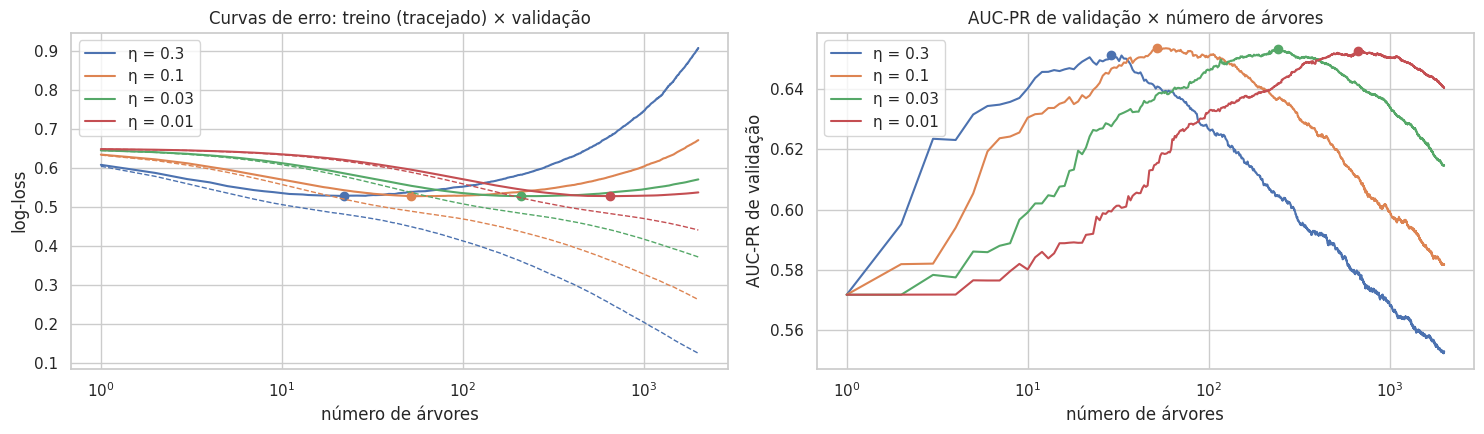

,learning_rate,árvores no mínimo da log-loss,log-loss mínima,árvores no máximo da AUC-PR,AUC-PR máxima,AUC-PR com 2.000 árvores,taxa × árvores (AUC-PR),tempo (s)
0,0.30,22,0.5279,29,0.6512,0.5527,8.70,55.1872
1,0.10,52,0.5273,52,0.6536,0.5817,5.20,22.7004
2,0.03,209,0.5275,243,0.6531,0.6146,7.29,22.9502
3,0.01,652,0.5274,668,0.6527,0.6404,6.68,20.3941


**Leitura dos resultados.** Com η = 0,3, a log-loss de validação atinge o mínimo com 22 árvores e, a partir daí, sobe, enquanto a de treino continua caindo: é o sobreajuste aparecendo em tempo real. Com η = 0,1, o mínimo ocorre com 52 árvores; com η = 0,03, com 209 árvores; e, com η = 0,01, com 652 árvores. Ou seja, à medida que a taxa diminui, o ponto ótimo se desloca para a direita, como previsto na Seção 1.3. A melhor AUC-PR de validação varia de 0,651 (η = 0,3) a 0,654 (η = 0,1). A diferença mais importante, no entanto, está na **estabilidade**: passando do ponto ótimo para 2.000 árvores, a AUC-PR perde 0,098 com η = 0,3 e 0,012 com η = 0,01. Em termos práticos, uma taxa pequena torna o modelo bem menos sensível à escolha exata do número de árvores, ao custo de mais tempo de treino. Por isso, nas buscas seguintes, `n_estimators` e `learning_rate` são sempre ajustados juntos.

In [5]:
TAXAS = [0.3, 0.1, 0.03, 0.01]
MAX_ARVORES = 2000
curvas = {}
for taxa in TAXAS:
    historicos = {"treino_logloss": [], "valid_logloss": [], "valid_aucpr": []}
    inicio = time.time()
    for i_tr, i_va in dobras.split(X_treino, y_treino):
        prep = PreprocessadorChurn().fit(X_treino.iloc[i_tr])
        Z_tr, Z_va = prep.transform(X_treino.iloc[i_tr]), prep.transform(X_treino.iloc[i_va])
        modelo = xgb.XGBClassifier(n_estimators=MAX_ARVORES, learning_rate=taxa, max_depth=3, tree_method="hist",
                                   eval_metric=["logloss", "aucpr"], random_state=config.RANDOM_STATE, n_jobs=-1)
        modelo.fit(Z_tr, y_treino.iloc[i_tr], eval_set=[(Z_tr, y_treino.iloc[i_tr]), (Z_va, y_treino.iloc[i_va])], verbose=False)
        resultado = modelo.evals_result()
        historicos["treino_logloss"].append(resultado["validation_0"]["logloss"])
        historicos["valid_logloss"].append(resultado["validation_1"]["logloss"])
        historicos["valid_aucpr"].append(resultado["validation_1"]["aucpr"])
    curvas[taxa] = {k: np.mean(v, axis=0) for k, v in historicos.items()} | {"tempo": time.time() - inicio}

fig, eixos = plt.subplots(1, 2, figsize=(15, 4.5))
arvores = np.arange(1, MAX_ARVORES + 1)
resumo_taxas = []
for cor, taxa in zip(["C0", "C1", "C2", "C3"], TAXAS):
    c = curvas[taxa]
    eixos[0].plot(arvores, c["treino_logloss"], "--", c=cor, lw=1)
    eixos[0].plot(arvores, c["valid_logloss"], "-", c=cor, label=f"η = {taxa}")
    eixos[1].plot(arvores, c["valid_aucpr"], "-", c=cor, label=f"η = {taxa}")
    i_ll, i_ap = int(np.argmin(c["valid_logloss"])), int(np.argmax(c["valid_aucpr"]))
    eixos[0].plot(i_ll + 1, c["valid_logloss"][i_ll], "o", c=cor)
    eixos[1].plot(i_ap + 1, c["valid_aucpr"][i_ap], "o", c=cor)
    resumo_taxas.append({"learning_rate": taxa, "árvores no mínimo da log-loss": i_ll + 1,
                         "log-loss mínima": c["valid_logloss"][i_ll], "árvores no máximo da AUC-PR": i_ap + 1,
                         "AUC-PR máxima": c["valid_aucpr"][i_ap], "AUC-PR com 2.000 árvores": c["valid_aucpr"][-1],
                         "taxa × árvores (AUC-PR)": taxa * (i_ap + 1), "tempo (s)": c["tempo"]})
eixos[0].set(xscale="log", xlabel="número de árvores", ylabel="log-loss", title="Curvas de erro: treino (tracejado) × validação")
eixos[1].set(xscale="log", xlabel="número de árvores", ylabel="AUC-PR de validação", title="AUC-PR de validação × número de árvores")
eixos[0].legend(); eixos[1].legend(); plt.tight_layout(); plt.show()

resumo_taxas = pd.DataFrame(resumo_taxas)
display(resumo_taxas.round(4))

r = resumo_taxas.set_index("learning_rate")
def otimo(taxa):
    n = int(r.loc[taxa, "árvores no mínimo da log-loss"])
    return f"mais de {MAX_ARVORES} árvores" if n >= MAX_ARVORES else f"{n} árvores"
perda = r["AUC-PR máxima"] - r["AUC-PR com 2.000 árvores"]        # quanto se perde passando do ponto ótimo
leitura(
    f"Com η = 0,3, a log-loss de validação atinge o mínimo com {otimo(0.3)} e, a partir daí, sobe, enquanto a de treino "
    f"continua caindo: é o sobreajuste aparecendo em tempo real. Com η = 0,1, o mínimo ocorre com {otimo(0.1)}; com η = 0,03, "
    f"com {otimo(0.03)}; e, com η = 0,01, com {otimo(0.01)}. "
    + ("Ou seja, à medida que a taxa diminui, o ponto ótimo se desloca para a direita, como previsto na Seção 1.3. "
       if r["árvores no mínimo da log-loss"].is_monotonic_increasing else
       "Ou seja, o ponto ótimo tende a se deslocar para a direita à medida que a taxa diminui, ainda que não de forma perfeitamente regular. ")
    + f"A melhor AUC-PR de validação varia de {br(r['AUC-PR máxima'].min())} (η = {num(r['AUC-PR máxima'].idxmin())}) a "
    f"{br(r['AUC-PR máxima'].max())} (η = {num(r['AUC-PR máxima'].idxmax())}). A diferença mais importante, no entanto, está na "
    f"**estabilidade**: passando do ponto ótimo para 2.000 árvores, a AUC-PR perde {br(perda[0.3])} com η = 0,3 e "
    f"{br(perda[0.01])} com η = 0,01. "
    + ("Em termos práticos, uma taxa pequena torna o modelo bem menos sensível à escolha exata do número de árvores, ao custo "
       "de mais tempo de treino. " if perda[0.01] < perda[0.3] else
       "Nesta base, portanto, a vantagem de estabilidade das taxas pequenas é menor do que a teoria sugere. ")
    + "Por isso, nas buscas seguintes, `n_estimators` e `learning_rate` são sempre ajustados juntos."
)

## 5. Busca em grade (`GridSearchCV`)

A grade foi montada a partir das curvas da Seção 4 e das recomendações da documentação do XGBoost e da literatura sobre bases tabulares pequenas. A principal preocupação é manter o número de combinações viável, já que cada uma custa 5 treinamentos de centenas de árvores:

| Hiperparâmetro | Valores | Justificativa |
| --- | --- | --- |
| `n_estimators` | 200, 500 | cobre a região ótima das taxas 0,1 e 0,03 vista na Seção 4 |
| `learning_rate` | 0,03; 0,1 | taxas moderadas; 0,3 sobreajusta e 0,01 exigiria milhares de árvores |
| `max_depth` | 2, 3, 4, 6 | de tocos com uma interação até o padrão da biblioteca |
| `subsample` | 0,8; 1,0 | com e sem amostragem de clientes |
| `colsample_bytree` | 0,7; 1,0 | com e sem amostragem de atributos |
| `gamma` | 0, 1 | sem e com ganho mínimo por divisão (poda embutida) |

São 128 combinações e 640 treinamentos. Os parâmetros de regularização `reg_alpha` e `reg_lambda`, assim como `min_child_weight`, ficam para o Optuna, que pode explorá-los em escala contínua sem multiplicar o custo. Para não disputar os núcleos do processador, o XGBoost usa um núcleo por modelo e o `GridSearchCV` paraleliza as combinações.

128 combinações × 5 dobras em 184 s
Melhor combinação: {'colsample_bytree': 0.7, 'gamma': 1, 'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 500, 'subsample': 0.8}


,n_estimators,learning_rate,max_depth,subsample,colsample_bytree,gamma,mean_train_AUC_PR,mean_test_AUC_PR,std_test_AUC_PR,mean_test_AUC_ROC
34,500,0.03,2,0.8,0.7,1,0.7159,0.6600,0.0143,0.7888
2,500,0.03,2,0.8,0.7,0,0.7169,0.6599,0.0146,0.7889
49,200,0.10,2,1.0,0.7,1,0.7065,0.6578,0.0138,0.7877
51,500,0.10,2,1.0,0.7,1,0.7065,0.6578,0.0138,0.7877
4,200,0.03,3,0.8,0.7,0,0.7204,0.6576,0.0124,0.7866
35,500,0.03,2,1.0,0.7,1,0.7061,0.6575,0.0124,0.7881
3,500,0.03,2,1.0,0.7,0,0.7147,0.6573,0.0168,0.7881
36,200,0.03,3,0.8,0.7,1,0.7200,0.6571,0.0120,0.7866
98,500,0.03,2,0.8,1.0,1,0.7191,0.6569,0.0146,0.7881
99,500,0.03,2,1.0,1.0,1,0.7095,0.6567,0.0148,0.7878


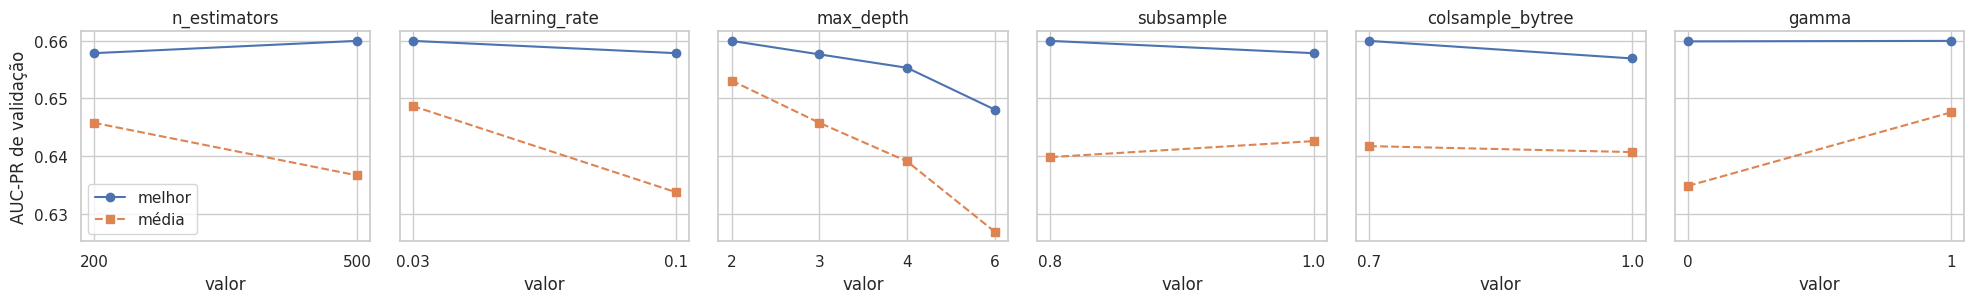

**Leitura dos resultados.** A grade levou 184 segundos, e a melhor combinação alcançou AUC-PR de validação de 0,660 ± 0,014, com afastamento de 0,056 para o treino. Nos gráficos de efeito marginal, a linha da média mostra quais escolhas importam em geral, e não apenas no vencedor. O hiperparâmetro mais decisivo é `max_depth`: a AUC-PR média vai de 0,653 (com 2) a 0,627 (com 6); em seguida vem `learning_rate`, com amplitude de 0,015, enquanto `colsample_bytree` quase não altera o resultado (amplitude de 0,001). Isso é coerente com o Relatório 04: em uma base pequena e ruidosa, árvores profundas dentro do ensemble reproduzem o mesmo sobreajuste da árvore isolada.

In [6]:
grade = {
    "modelo__n_estimators": [200, 500],
    "modelo__learning_rate": [0.03, 0.1],
    "modelo__max_depth": [2, 3, 4, 6],
    "modelo__subsample": [0.8, 1.0],
    "modelo__colsample_bytree": [0.7, 1.0],
    "modelo__gamma": [0, 1],
}
inicio = time.time()
busca_grade = GridSearchCV(pipeline_xgb(n_jobs=1), grade, cv=dobras, scoring=METRICAS, refit="AUC_PR",
                           return_train_score=True, n_jobs=-1).fit(X_treino, y_treino)
tempo_grade = time.time() - inicio

resultados_grade = pd.DataFrame(busca_grade.cv_results_)
resultados_grade.columns = [c.replace("param_modelo__", "") for c in resultados_grade.columns]
resultados_grade = resultados_grade.sort_values("rank_test_AUC_PR")
melhores_grade = {k.replace("modelo__", ""): v for k, v in busca_grade.best_params_.items()}
print(f"{len(resultados_grade)} combinações × {config.N_DOBRAS} dobras em {tempo_grade:.0f} s")
print(f"Melhor combinação: {melhores_grade}")
display(resultados_grade[["n_estimators", "learning_rate", "max_depth", "subsample", "colsample_bytree", "gamma",
                          "mean_train_AUC_PR", "mean_test_AUC_PR", "std_test_AUC_PR", "mean_test_AUC_ROC"]].head(10).round(4))

# Efeito marginal de cada hiperparâmetro: melhor AUC-PR para cada valor (os demais livres).
grade_nomes = ["n_estimators", "learning_rate", "max_depth", "subsample", "colsample_bytree", "gamma"]
fig, eixos = plt.subplots(1, 6, figsize=(20, 3.2), sharey=True)
for eixo, parametro in zip(eixos, grade_nomes):
    efeito = resultados_grade.groupby(parametro)["mean_test_AUC_PR"].agg(["max", "mean"])
    eixo.plot(efeito.index.astype(str), efeito["max"], "o-", label="melhor")
    eixo.plot(efeito.index.astype(str), efeito["mean"], "s--", label="média")
    eixo.set(title=parametro, xlabel="valor")
eixos[0].set_ylabel("AUC-PR de validação"); eixos[0].legend(); plt.tight_layout(); plt.show()

melhor = resultados_grade.iloc[0]
medias = {p: resultados_grade.groupby(p)["mean_test_AUC_PR"].mean() for p in grade_nomes}
amplitude = pd.Series({p: m.max() - m.min() for p, m in medias.items()}).sort_values(ascending=False)
decisivo, segundo = amplitude.index[0], amplitude.index[1]
m = medias[decisivo]
leitura(
    f"A grade levou {tempo_grade:.0f} segundos, e a melhor combinação alcançou AUC-PR de validação de "
    f"{br(melhor['mean_test_AUC_PR'])} ± {br(melhor['std_test_AUC_PR'])}, com afastamento de "
    f"{br(melhor['mean_train_AUC_PR'] - melhor['mean_test_AUC_PR'])} para o treino. Nos gráficos de efeito marginal, a linha "
    f"da média mostra quais escolhas importam em geral, e não apenas no vencedor. O hiperparâmetro mais decisivo é "
    f"`{decisivo}`: a AUC-PR média vai de {br(m.max())} (com {num(m.idxmax())}) a {br(m.min())} (com {num(m.idxmin())}); "
    f"em seguida vem `{segundo}`, com amplitude de {br(amplitude[segundo])}, enquanto `{amplitude.index[-1]}` quase não altera "
    f"o resultado (amplitude de {br(amplitude.iloc[-1])}). "
    + ("Isso é coerente com o Relatório 04: em uma base pequena e ruidosa, árvores profundas dentro do ensemble reproduzem "
       "o mesmo sobreajuste da árvore isolada." if decisivo == "max_depth" and m.idxmax() < m.idxmin() else "")
)

## 6. Otimização bayesiana com Optuna

### 6.1 Espaço de busca e função objetivo

O espaço de busca do Optuna inclui os oito hiperparâmetros do miniprojeto e mais dois, que a pesquisa da equipe indicou como relevantes para bases pequenas e desbalanceadas:

| Hiperparâmetro | Faixa | Escala | Justificativa |
| --- | --- | --- | --- |
| `n_estimators` | 100 a 1.500 | log | cobre o ótimo de todas as taxas da Seção 4, exceto 0,01 com muitas árvores |
| `learning_rate` | 0,005 a 0,3 | log | do passo muito pequeno ao padrão; a escala log dá o mesmo peso a cada ordem de grandeza |
| `max_depth` | 2 a 8 | linear | de tocos a árvores profundas |
| `min_child_weight` | 1 a 50 | log | **extra**: soma mínima de "peso" (hessiana) em uma folha, o equivalente ao `min_samples_leaf`, que foi o melhor controle no Relatório 04 |
| `subsample` | 0,5 a 1,0 | linear | fração de clientes por árvore |
| `colsample_bytree` | 0,4 a 1,0 | linear | fração de atributos por árvore |
| `gamma` | 0 a 5 | linear | ganho mínimo por divisão |
| `reg_alpha` | 10⁻⁸ a 10 | log | regularização L1 das folhas |
| `reg_lambda` | 10⁻³ a 50 | log | regularização L2 das folhas |
| `scale_pos_weight` | 1 a 3 | linear | **extra**: peso da classe churn (a razão entre as classes é cerca de 1,8); testa de novo, agora no boosting, a hipótese do balanceamento |

A função objetivo treina o `Pipeline` em cada uma das 5 dobras e devolve a AUC-PR média, exatamente como o `GridSearchCV`. A diferença é que, depois de cada dobra, ela informa ao Optuna a média parcial (`trial.report`). Com isso, o ***MedianPruner*** pode interromper a tentativa se, a partir da segunda dobra, a média parcial estiver abaixo da mediana das tentativas anteriores no mesmo ponto. As 10 primeiras tentativas nunca são interrompidas, para que o pruner tenha uma referência.

O número de tentativas (`N_TENTATIVAS`) foi fixado em 80, com um limite de tempo de 20 minutos, valores que cabem com folga em uma sessão do Colab. Se houver mais tempo disponível, aumentar o número de tentativas tende a melhorar levemente o resultado.

In [7]:
N_TENTATIVAS = 80
TEMPO_LIMITE = 20 * 60   # segundos

def objetivo(trial):
    hp = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1500, log=True),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 50, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 50.0, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 3.0),
    }
    notas = []
    for passo, (i_tr, i_va) in enumerate(dobras.split(X_treino, y_treino)):
        modelo = pipeline_xgb(**hp).fit(X_treino.iloc[i_tr], y_treino.iloc[i_tr])
        notas.append(average_precision_score(y_treino.iloc[i_va], modelo.predict_proba(X_treino.iloc[i_va])[:, 1]))
        trial.report(float(np.mean(notas)), passo)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("desvio", float(np.std(notas)))
    return float(np.mean(notas))

estudo = optuna.create_study(direction="maximize", study_name="xgboost_churn",
                             sampler=optuna.samplers.TPESampler(seed=config.RANDOM_STATE),
                             pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1))
inicio = time.time()
estudo.optimize(objetivo, n_trials=N_TENTATIVAS, timeout=TEMPO_LIMITE, show_progress_bar=False)
tempo_optuna = time.time() - inicio

tentativas = estudo.trials_dataframe()
estado = tentativas["state"].astype(str).str.replace("TrialState.", "", regex=False)
n_completas, n_podadas = int((estado == "COMPLETE").sum()), int((estado == "PRUNED").sum())
melhores_optuna = estudo.best_params
print(f"{len(tentativas)} tentativas em {tempo_optuna:.0f} s: {n_completas} completas e {n_podadas} interrompidas pelo pruner")
print(f"Melhor tentativa (nº {estudo.best_trial.number}): AUC-PR = {estudo.best_value:.4f} "
      f"± {estudo.best_trial.user_attrs.get('desvio', float('nan')):.4f}")
display(pd.Series(melhores_optuna, name="melhor valor").to_frame().round(4))

80 tentativas em 159 s: 65 completas e 15 interrompidas pelo pruner
Melhor tentativa (nº 61): AUC-PR = 0.6634 ± 0.0108


,melhor valor
n_estimators,720.0000
learning_rate,0.0312
max_depth,2.0000
min_child_weight,1.6540
subsample,0.6506
colsample_bytree,0.4882
gamma,4.4651
reg_alpha,0.0687
reg_lambda,0.1298
scale_pos_weight,1.0227


### 6.2 O que o Optuna aprendeu sobre o espaço de busca

Os gráficos abaixo mostram, da esquerda para a direita: o histórico da otimização (cada ponto é uma tentativa completa, e a linha acompanha o melhor valor até então); a importância de cada hiperparâmetro, calculada pelo Optuna com o método fANOVA, que estima quanto da variação da AUC-PR se deve a cada um; e, por fim, a relação entre a taxa de aprendizado e o número de árvores nas tentativas completas, colorida pela AUC-PR, que permite verificar se a busca automática redescobriu o compromisso da Seção 4.

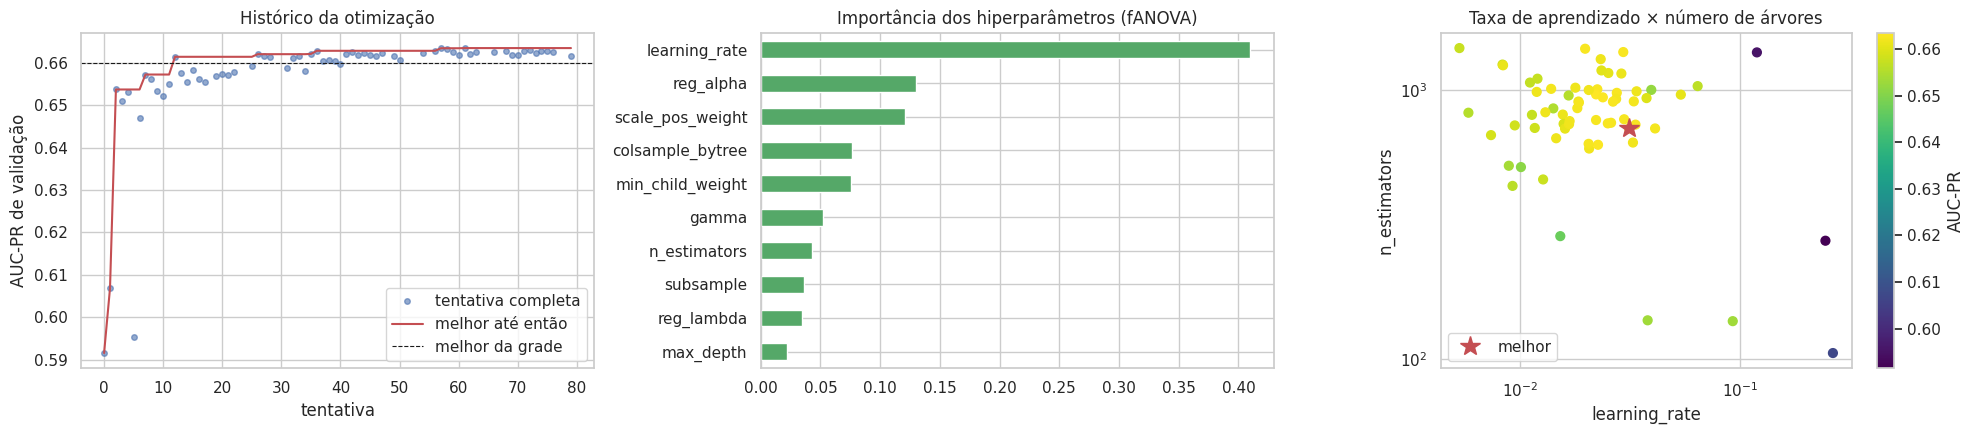

**Leitura dos resultados.** Os dois hiperparâmetros que mais explicam a variação da AUC-PR são `learning_rate` e `reg_alpha`, ao passo que `max_depth` praticamente não influencia o resultado. O Optuna superou o melhor resultado da grade pela primeira vez na tentativa 12. Além disso, entre as 13 tentativas de maior AUC-PR (o quinto superior), a correlação entre o logaritmo da taxa e o logaritmo do número de árvores é de -0,20, o que indica que, nesta busca, outros hiperparâmetros (como a profundidade e a regularização) pesaram mais do que o par taxa × árvores na separação entre boas e más configurações.

In [8]:
completas = tentativas[estado == "COMPLETE"].copy()
importancia_hp = pd.Series(optuna.importance.get_param_importances(estudo)).sort_values()

fig, eixos = plt.subplots(1, 3, figsize=(20, 4.5))
eixos[0].plot(completas["number"], completas["value"], "o", ms=4, alpha=0.6, label="tentativa completa")
eixos[0].plot(completas["number"], completas["value"].cummax(), "-", c="C3", label="melhor até então")
eixos[0].axhline(resultados_grade["mean_test_AUC_PR"].max(), c="k", ls="--", lw=0.8, label="melhor da grade")
eixos[0].set(xlabel="tentativa", ylabel="AUC-PR de validação", title="Histórico da otimização")
eixos[0].legend()
importancia_hp.plot.barh(ax=eixos[1], color="C2", title="Importância dos hiperparâmetros (fANOVA)")
mapa = eixos[2].scatter(completas["params_learning_rate"], completas["params_n_estimators"], c=completas["value"],
                        cmap="viridis", s=40)
eixos[2].plot(melhores_optuna["learning_rate"], melhores_optuna["n_estimators"], "r*", ms=15, label="melhor")
eixos[2].set(xscale="log", yscale="log", xlabel="learning_rate", ylabel="n_estimators",
             title="Taxa de aprendizado × número de árvores")
plt.colorbar(mapa, ax=eixos[2], label="AUC-PR"); eixos[2].legend()
plt.tight_layout(); plt.show()

correlacao = np.corrcoef(np.log(completas["params_learning_rate"]), np.log(completas["params_n_estimators"]))[0, 1]
top = completas.nlargest(max(5, len(completas) // 5), "value")
correlacao_top = np.corrcoef(np.log(top["params_learning_rate"]), np.log(top["params_n_estimators"]))[0, 1]
primeiro_melhor_grade = completas.loc[completas["value"] >= resultados_grade["mean_test_AUC_PR"].max(), "number"]
leitura(
    f"Os dois hiperparâmetros que mais explicam a variação da AUC-PR são `{importancia_hp.index[-1]}` e "
    f"`{importancia_hp.index[-2]}`, ao passo que `{importancia_hp.index[0]}` praticamente não influencia o resultado. "
    + (f"O Optuna superou o melhor resultado da grade pela primeira vez na tentativa {int(primeiro_melhor_grade.iloc[0])}. "
       if len(primeiro_melhor_grade) else "Em nenhuma tentativa o Optuna superou o melhor resultado da grade. ")
    + f"Além disso, entre as {len(top)} tentativas de maior AUC-PR (o quinto superior), a correlação entre o logaritmo da "
    f"taxa e o logaritmo do número de árvores é de {br(correlacao_top, 2)}"
    + (", ou seja, a busca automática redescobriu o compromisso da Seção 4: as boas configurações com taxa menor são "
       "justamente as que usam mais árvores." if correlacao_top < -0.3 else
       ", o que indica que, nesta busca, outros hiperparâmetros (como a profundidade e a regularização) pesaram mais "
       "do que o par taxa × árvores na separação entre boas e más configurações.")
)

## 7. Grade × Optuna: escolha do XGBoost

Os dois mecanismos de busca são comparados em três dimensões: o melhor resultado de validação, o custo computacional (número de treinamentos e tempo) e a complexidade do modelo encontrado. Para garantir uma comparação justa, a melhor configuração de cada busca é reavaliada com a mesma função `avaliar_cv` e as mesmas dobras.

Há, entretanto, um cuidado metodológico importante. Quando se testam muitas configurações e se escolhe a melhor, a nota dessa melhor configuração é **otimista**, porque parte do seu desempenho pode ser sorte nas dobras (a chamada "maldição do vencedor"). Esse efeito é maior quanto mais configurações são comparadas. Por isso, a escolha entre os dois finalistas usa a mesma regra do Relatório 04: fica o de maior AUC-PR, **a menos que** a diferença seja menor que um erro padrão; nesse caso, preferimos o modelo mais simples, com menos árvores e menor profundidade. O teste, que nenhuma das buscas viu, dará a palavra final sobre o otimismo.

In [9]:
finalistas = {"XGBoost — GridSearchCV": melhores_grade, "XGBoost — Optuna": melhores_optuna}
linhas = []
for nome, hp in finalistas.items():
    linha = avaliar_cv(pipeline_xgb(**hp), nome)
    linha.update({"árvores": hp["n_estimators"], "profundidade": hp["max_depth"], "hp": hp})
    linhas.append(linha)
comparacao_buscas = pd.DataFrame(linhas).set_index("modelo")
comparacao_buscas["treinamentos na busca"] = [len(resultados_grade) * config.N_DOBRAS,
                                              int(sum(len(t.intermediate_values) if hasattr(t, "intermediate_values") else
                                                      len(getattr(t, "inter", {})) for t in estudo.trials))]
comparacao_buscas["tempo da busca (s)"] = [tempo_grade, tempo_optuna]
display(comparacao_buscas[["AUC_PR (treino)", "AUC_PR (validação)", "AUC_PR desvio (validação)", "AUC_ROC (validação)",
                           "árvores", "profundidade", "treinamentos na busca", "tempo da busca (s)"]].round(4))

ordenadas = comparacao_buscas.sort_values("AUC_PR (validação)", ascending=False)
ep = ordenadas["AUC_PR desvio (validação)"].iloc[0] / np.sqrt(config.N_DOBRAS)
diferenca = ordenadas["AUC_PR (validação)"].iloc[0] - ordenadas["AUC_PR (validação)"].iloc[1]
if diferenca < ep:      # empate estatístico: fica o mais simples (menos árvores × profundidade)
    nome_xgb = (comparacao_buscas["árvores"] * comparacao_buscas["profundidade"]).idxmin()
else:
    nome_xgb = ordenadas.index[0]
hp_xgb = comparacao_buscas.loc[nome_xgb, "hp"]
print(f"Diferença de AUC-PR: {diferenca:.4f} | erro padrão: {ep:.4f} -> escolhido: {nome_xgb}")

g, o = comparacao_buscas.loc["XGBoost — GridSearchCV"], comparacao_buscas.loc["XGBoost — Optuna"]
leitura(
    f"O Optuna obteve AUC-PR de validação de {br(o['AUC_PR (validação)'])} e a grade, de {br(g['AUC_PR (validação)'])}; "
    f"a diferença ({br(abs(o['AUC_PR (validação)'] - g['AUC_PR (validação)']), 4)}) é "
    f"{'menor' if diferenca < ep else 'maior'} que um erro padrão ({br(ep, 4)}). "
    f"Em custo, a grade fez {int(g['treinamentos na busca'])} treinamentos em {g['tempo da busca (s)']:.0f} s, enquanto o Optuna fez "
    f"{int(o['treinamentos na busca'])} em {o['tempo da busca (s)']:.0f} s, interrompendo {n_podadas} tentativas pelo caminho. "
    f"Pela regra de escolha, ficou o modelo encontrado pelo **{nome_xgb.split('— ')[1]}**, com {hp_xgb['n_estimators']} "
    f"árvores de profundidade até {hp_xgb['max_depth']} e taxa de aprendizado {num(hp_xgb['learning_rate'])}. "
    + ("A vantagem do Optuna, nesse caso, não está só na nota, mas no fato de explorar dez hiperparâmetros em escala contínua "
       "com um custo comparável ao de uma grade de seis hiperparâmetros com dois a quatro valores cada."
       if o["AUC_PR (validação)"] >= g["AUC_PR (validação)"] else
       "Isso mostra que, em uma base pequena, uma grade bem informada pelas curvas da Seção 4 já captura quase todo o ganho "
       "disponível, e que a busca bayesiana não é garantia de um resultado melhor.")
)

,AUC_PR (treino),AUC_PR (validação),AUC_PR desvio (validação),AUC_ROC (validação),árvores,profundidade,treinamentos na busca,tempo da busca (s)
modelo,,,,,,,,
XGBoost — GridSearchCV,0.7159,0.6600,0.0143,0.7888,500,2,640,184.4741
XGBoost — Optuna,0.6973,0.6634,0.0108,0.7898,720,2,365,158.6184


Diferença de AUC-PR: 0.0035 | erro padrão: 0.0048 -> escolhido: XGBoost — GridSearchCV


**Leitura dos resultados.** O Optuna obteve AUC-PR de validação de 0,663 e a grade, de 0,660; a diferença (0,0035) é menor que um erro padrão (0,0048). Em custo, a grade fez 640 treinamentos em 184 s, enquanto o Optuna fez 365 em 159 s, interrompendo 15 tentativas pelo caminho. Pela regra de escolha, ficou o modelo encontrado pelo **GridSearchCV**, com 500 árvores de profundidade até 2 e taxa de aprendizado 0,03. A vantagem do Optuna, nesse caso, não está só na nota, mas no fato de explorar dez hiperparâmetros em escala contínua com um custo comparável ao de uma grade de seis hiperparâmetros com dois a quatro valores cada.

## 8. O limiar de decisão

O limiar é escolhido exatamente como no Relatório 04: com as previsões fora da dobra do modelo escolhido, tomamos o **maior limiar que garante pelo menos 80% de recall**. Diferentemente da árvore, contudo, o XGBoost produz probabilidades praticamente contínuas, porque cada cliente recebe a soma de centenas de pequenas contribuições. Por isso, o recall pode ser ajustado de forma fina, sem os "degraus" que impediam a árvore de atingir a meta com precisão.

A tabela de metas repete a análise do trade-off entre recall e precisão, agora com as duas colunas lado a lado: a da árvore, recalculada com as mesmas dobras, e a do XGBoost.

,recall-alvo,precisão árvore,% acionados árvore,precisão XGBoost,% acionados XGBoost
0,0.60,0.583,0.366,0.611,0.348
1,0.70,0.557,0.446,0.586,0.423
2,0.80,0.519,0.547,0.537,0.528
3,0.90,0.460,0.696,0.483,0.660
4,0.95,0.428,0.788,0.441,0.764


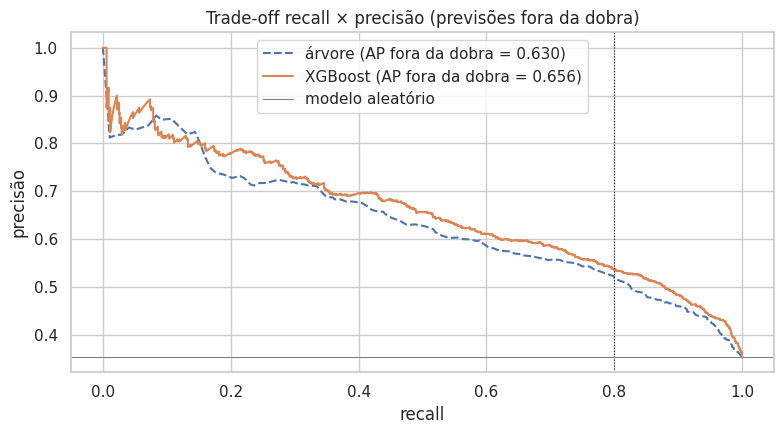

Limiar do XGBoost para recall ≥ 80%: 0.2901


**Leitura dos resultados.** No ponto de operação de 80% de recall, o XGBoost tem precisão fora da dobra de 53,7% e aciona 52,8% dos clientes, contra 51,9% e 54,7% da árvore. Em todas as metas de recall da tabela, o XGBoost tem precisão maior que a árvore e, portanto, aciona menos clientes desnecessariamente para antecipar a mesma fração de cancelamentos.

In [10]:
modelo_xgb = pipeline_xgb(**hp_xgb)
prob_oof_xgb = cross_val_predict(modelo_xgb, X_treino, y_treino, cv=dobras, method="predict_proba")[:, 1]
prob_oof_arv = cross_val_predict(pipeline_arvore(**hp_arvore), X_treino, y_treino, cv=dobras, method="predict_proba")[:, 1]
limiar_xgb = limiar_para_recall(prob_oof_xgb, y_treino)
limiar_arv = arvore_json["limiar"]

tradeoff = []
for alvo in [0.60, 0.70, 0.80, 0.90, 0.95]:
    linha = {"recall-alvo": alvo}
    for nome, prob in [("árvore", prob_oof_arv), ("XGBoost", prob_oof_xgb)]:
        t = limiar_para_recall(prob, y_treino, alvo)
        linha[f"precisão {nome}"] = precision_score(y_treino, prob >= t)
        linha[f"% acionados {nome}"] = (prob >= t).mean()
    tradeoff.append(linha)
tradeoff = pd.DataFrame(tradeoff)
display(tradeoff.round(3))

fig, eixo = plt.subplots(figsize=(8, 4.5))
for nome, prob, estilo in [("árvore", prob_oof_arv, "--"), ("XGBoost", prob_oof_xgb, "-")]:
    prec, rec, _ = precision_recall_curve(y_treino, prob)
    eixo.plot(rec, prec, estilo, label=f"{nome} (AP fora da dobra = {average_precision_score(y_treino, prob):.3f})")
eixo.axvline(config.RECALL_ALVO, c="k", ls=":", lw=0.8)
eixo.axhline(y_treino.mean(), c="grey", lw=0.8, label="modelo aleatório")
eixo.set(xlabel="recall", ylabel="precisão", title="Trade-off recall × precisão (previsões fora da dobra)")
eixo.legend(); plt.tight_layout(); plt.show()

m80 = tradeoff[tradeoff["recall-alvo"] == 0.80].iloc[0]
print(f"Limiar do XGBoost para recall ≥ {config.RECALL_ALVO:.0%}: {limiar_xgb:.4f}")
leitura(
    f"No ponto de operação de 80% de recall, o XGBoost tem precisão fora da dobra de {pct(m80['precisão XGBoost'])} e aciona "
    f"{pct(m80['% acionados XGBoost'])} dos clientes, contra {pct(m80['precisão árvore'])} e {pct(m80['% acionados árvore'])} da árvore. "
    + ("Em todas as metas de recall da tabela, o XGBoost tem precisão maior que a árvore e, portanto, aciona menos clientes "
       "desnecessariamente para antecipar a mesma fração de cancelamentos."
       if (tradeoff["precisão XGBoost"] >= tradeoff["precisão árvore"]).all() else
       "Em algumas metas de recall da tabela o XGBoost é mais preciso, mas em outras não; assim, a vantagem de um modelo "
       "sobre o outro depende da meta escolhida." if (tradeoff["precisão XGBoost"] >= tradeoff["precisão árvore"]).any() else
       "Em todas as metas de recall da tabela, a árvore tem precisão igual ou maior que o XGBoost.")
)

## 9. Avaliação final no teste e análise de sobreajuste

### 9.1 Métricas no treino e no teste

Como no Relatório 04, o XGBoost escolhido é treinado com o treino inteiro e avaliado **uma única vez** no teste, com o limiar da Seção 8. A tabela mostra as métricas nos dois conjuntos e o ***gap*** entre eles.

In [11]:
inicio = time.time()
xgb_final = pipeline_xgb(**hp_xgb).fit(X_treino, y_treino)
tempo_treino_xgb = time.time() - inicio
# Árvore de referência treinada nas mesmas condições (para as comparações das Seções 9 a 11).
inicio = time.time()
arvore_final = pipeline_arvore(**hp_arvore).fit(X_treino, y_treino)
tempo_treino_arv = time.time() - inicio
prob_treino_arv, prob_teste_arv = arvore_final.predict_proba(X_treino)[:, 1], arvore_final.predict_proba(X_teste)[:, 1]
m_tr_arv, m_te_arv = metricas(y_treino, prob_treino_arv, limiar_arv), metricas(y_teste, prob_teste_arv, limiar_arv)
prob_treino = xgb_final.predict_proba(X_treino)[:, 1]
prob_teste = xgb_final.predict_proba(X_teste)[:, 1]
m_tr, m_te = metricas(y_treino, prob_treino, limiar_xgb), metricas(y_teste, prob_teste, limiar_xgb)
gap = pd.DataFrame({"treino": m_tr, "teste": m_te}).T
gap.loc["gap (treino − teste)"] = gap.loc["treino"] - gap.loc["teste"]
print(f"XGBoost escolhido ({nome_xgb}), limiar {limiar_xgb:.4f}, treinado em {tempo_treino_xgb:.1f} s:")
display(gap.round(3))

cv_ap = comparacao_buscas.loc[nome_xgb, "AUC_PR (validação)"]
dif_cv = cv_ap - m_te["AUC-PR"]
gap_ap, gap_ap_arv = m_tr["AUC-PR"] - m_te["AUC-PR"], m_tr_arv["AUC-PR"] - m_te_arv["AUC-PR"]
leitura(
    f"No teste, o XGBoost antecipa {pct(m_te['recall'])} dos cancelamentos com precisão de {pct(m_te['precisão'])}, acionando "
    f"{pct(m_te['% acionados'])} dos clientes; a AUC-PR é de {br(m_te['AUC-PR'])} e a AUC-ROC, de {br(m_te['AUC-ROC'])}. "
    + (f"A AUC-PR de teste ficou próxima da estimativa da validação cruzada ({br(cv_ap)}), o que indica que o otimismo da "
       f"escolha entre muitas configurações foi pequeno. " if abs(dif_cv) < 0.02 else
       f"A AUC-PR de teste ficou {br(dif_cv)} abaixo da estimativa da validação cruzada ({br(cv_ap)}), o que reflete, ao menos "
       f"em parte, o otimismo da escolha entre muitas configurações. " if dif_cv > 0 else
       f"A AUC-PR de teste ficou {br(-dif_cv)} acima da estimativa da validação cruzada ({br(cv_ap)}); como o teste é uma "
       f"amostra finita, essa variação é natural e, de todo modo, não há sinal de otimismo na escolha. ")
    + f"O gap entre treino e teste é de {br(gap_ap)} na AUC-PR e de {br(gap.loc['gap (treino − teste)', 'recall'])} no recall; "
    f"para comparação, o gap da árvore na AUC-PR é de {br(gap_ap_arv)}. "
    + ("O ensemble, portanto, sobreajusta mais que a árvore, um comportamento comum em boosting, já que as árvores tardias "
       "se especializam nos clientes difíceis do treino; o que importa, porém, é o desempenho no teste, comparado na Seção 11."
       if gap_ap > gap_ap_arv + 0.01 else
       "O ensemble, portanto, não sobreajusta mais que a árvore, o que mostra que a regularização encontrada na busca "
       "foi eficaz.")
)

XGBoost escolhido (XGBoost — GridSearchCV), limiar 0.2901, treinado em 0.2 s:


,recall,precisão,F2,acurácia,% acionados,AUC-ROC,AUC-PR
treino,0.826,0.556,0.753,0.704,0.527,0.818,0.708
teste,0.798,0.542,0.729,0.690,0.521,0.803,0.680
gap (treino − teste),0.028,0.013,0.023,0.014,0.005,0.016,0.028


**Leitura dos resultados.** No teste, o XGBoost antecipa 79,8% dos cancelamentos com precisão de 54,2%, acionando 52,1% dos clientes; a AUC-PR é de 0,680 e a AUC-ROC, de 0,803. A AUC-PR de teste ficou próxima da estimativa da validação cruzada (0,660), o que indica que o otimismo da escolha entre muitas configurações foi pequeno. O gap entre treino e teste é de 0,028 na AUC-PR e de 0,028 no recall; para comparação, o gap da árvore na AUC-PR é de 0,060. O ensemble, portanto, não sobreajusta mais que a árvore, o que mostra que a regularização encontrada na busca foi eficaz.

### 9.2 Matriz de confusão, curvas ROC e precisão-recall e curva de aprendizado

Os gráficos repetem os do Relatório 04, com uma diferença: a curva de aprendizado (à direita) mostra o XGBoost e a árvore no mesmo eixo, o que permite comparar como cada um aproveita o aumento da quantidade de dados.

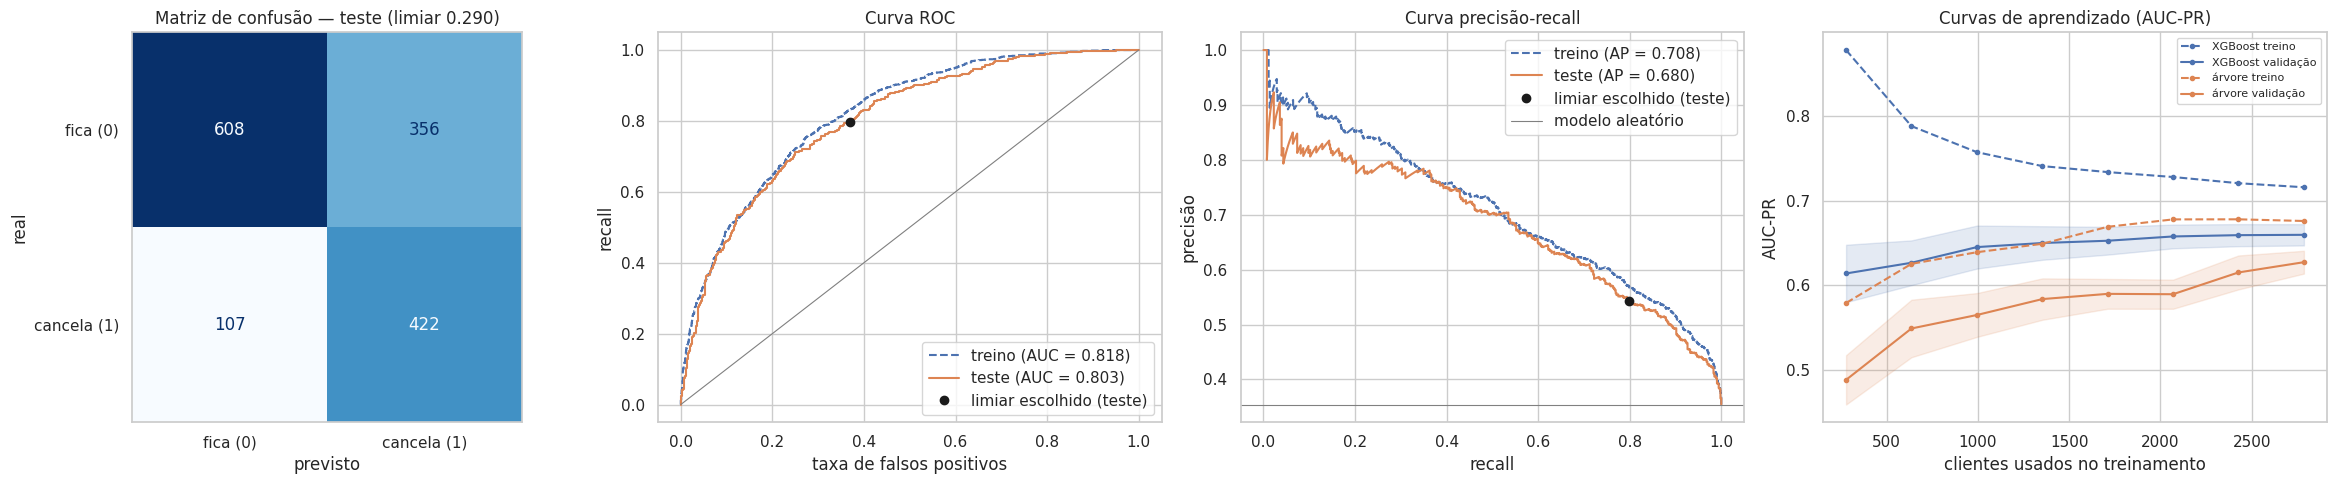

**Leitura dos resultados.** Em números absolutos, o XGBoost antecipa 422 dos 529 cancelamentos do teste e deixa escapar 107, acionando 778 clientes, dos quais 356 não cancelariam. Isso equivale a 1,84 clientes acionados por cancelamento detectado (a árvore precisa de 1,88 e a escolha aleatória, de 2,82). Na curva de aprendizado, a AUC-PR de validação do XGBoost passa de 0,614 com 278 clientes para 0,660 com o treino completo e já se aproxima de um patamar no final.

In [12]:
fig, eixos = plt.subplots(1, 4, figsize=(24, 5))
ConfusionMatrixDisplay.from_predictions(y_teste, (prob_teste >= limiar_xgb).astype(int), display_labels=["fica (0)", "cancela (1)"],
                                        cmap="Blues", ax=eixos[0], colorbar=False)
eixos[0].set(title=f"Matriz de confusão — teste (limiar {limiar_xgb:.3f})", xlabel="previsto", ylabel="real"); eixos[0].grid(False)
for conjunto, y, prob, estilo in [("treino", y_treino, prob_treino, "--"), ("teste", y_teste, prob_teste, "-")]:
    fpr, tpr, _ = roc_curve(y, prob)
    eixos[1].plot(fpr, tpr, estilo, label=f"{conjunto} (AUC = {roc_auc_score(y, prob):.3f})")
    prec, rec, _ = precision_recall_curve(y, prob)
    eixos[2].plot(rec, prec, estilo, label=f"{conjunto} (AP = {average_precision_score(y, prob):.3f})")
fpr_ponto = ((prob_teste >= limiar_xgb) & (y_teste == 0)).sum() / (y_teste == 0).sum()
eixos[1].plot(fpr_ponto, m_te["recall"], "ko", label="limiar escolhido (teste)"); eixos[1].plot([0, 1], [0, 1], c="grey", lw=0.8)
eixos[1].set(title="Curva ROC", xlabel="taxa de falsos positivos", ylabel="recall")
eixos[2].plot(m_te["recall"], m_te["precisão"], "ko", label="limiar escolhido (teste)")
eixos[2].axhline(y_teste.mean(), c="grey", lw=0.8, label="modelo aleatório")
eixos[2].set(title="Curva precisão-recall", xlabel="recall", ylabel="precisão")
eixos[1].legend(); eixos[2].legend()

fracoes = np.linspace(0.1, 1.0, 8)
for nome, modelo, cor in [("XGBoost", pipeline_xgb(**hp_xgb), "C0"), ("árvore", pipeline_arvore(**hp_arvore), "C1")]:
    n, tr, va = learning_curve(modelo, X_treino, y_treino, cv=dobras, scoring="average_precision", train_sizes=fracoes,
                               shuffle=True, random_state=config.RANDOM_STATE)
    eixos[3].plot(n, tr.mean(axis=1), "--o", c=cor, ms=3, label=f"{nome} treino")
    eixos[3].plot(n, va.mean(axis=1), "-o", c=cor, ms=3, label=f"{nome} validação")
    eixos[3].fill_between(n, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), color=cor, alpha=0.15)
    if nome == "XGBoost":
        va_xgb = va.mean(axis=1)
eixos[3].set(title="Curvas de aprendizado (AUC-PR)", xlabel="clientes usados no treinamento", ylabel="AUC-PR"); eixos[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

vp = int(((prob_teste >= limiar_xgb) & (y_teste == 1)).sum()); fn = int((y_teste == 1).sum()) - vp
fp = int(((prob_teste >= limiar_xgb) & (y_teste == 0)).sum())
por_churn_arv = (prob_teste_arv >= limiar_arv).sum() / ((prob_teste_arv >= limiar_arv) & (y_teste == 1)).sum()
leitura(
    f"Em números absolutos, o XGBoost antecipa {vp} dos {vp + fn} cancelamentos do teste e deixa escapar {fn}, acionando "
    f"{vp + fp} clientes, dos quais {fp} não cancelariam. Isso equivale a {br((vp + fp) / vp, 2)} clientes acionados por "
    f"cancelamento detectado (a árvore precisa de {br(por_churn_arv, 2)} e a escolha aleatória, de {br(1 / y_teste.mean(), 2)}). "
    f"Na curva de aprendizado, a AUC-PR de validação do XGBoost passa de {br(va_xgb[0])} com {int(n[0])} clientes para "
    f"{br(va_xgb[-1])} com o treino completo"
    + (" e ainda está subindo no final, indicando que mais dados continuariam a ajudar."
       if va_xgb[-1] - va_xgb[-2] > 0.003 else " e já se aproxima de um patamar no final.")
)

## 10. Interpretação do XGBoost

### 10.1 Três visões de importância

Um ensemble de centenas de árvores não pode ser lido como uma única árvore; por isso, a sua interpretação depende de medidas de importância. Usamos três, cada uma respondendo a uma pergunta diferente:

- **Ganho total (*total_gain*)**: a redução total da perda proporcionada por todas as divisões que usam a variável, somada sobre as árvores. É o análogo da MDI do Relatório 04 e herda o mesmo viés a favor de variáveis contínuas. Usamos o ganho total, e não o médio, porque ele pode ser somado entre as colunas one-hot de uma mesma variável.
- **Frequência (*weight*)**: quantas vezes a variável foi usada em uma divisão. Variáveis contínuas tendem a ser usadas muitas vezes para ajustes finos, mesmo que cada uso contribua pouco.
- **Permutação no teste**: quanto a AUC-PR de teste cai quando a variável é embaralhada, exatamente como no Relatório 04. É a medida diretamente comparável entre os dois modelos.

Como antes, as colunas one-hot são somadas na variável original.

,total_gain,weight,permutação XGBoost,permutação árvore
tipo_contrato,0.234,0.120,0.091,0.089
tempo_cliente_meses,0.264,0.244,0.077,0.063
chamados_totais,0.202,0.134,0.073,0.059
atrasos_6m,0.118,0.129,0.050,0.037
mensalidade_rs,0.124,0.278,0.021,0.028
debito_automatico,0.026,0.047,0.016,0.000
fibra_optica,0.025,0.023,0.006,0.005
forma_pagamento,0.005,0.018,0.000,-0.001
mensalidade_ausente,0.001,0.006,0.000,0.000


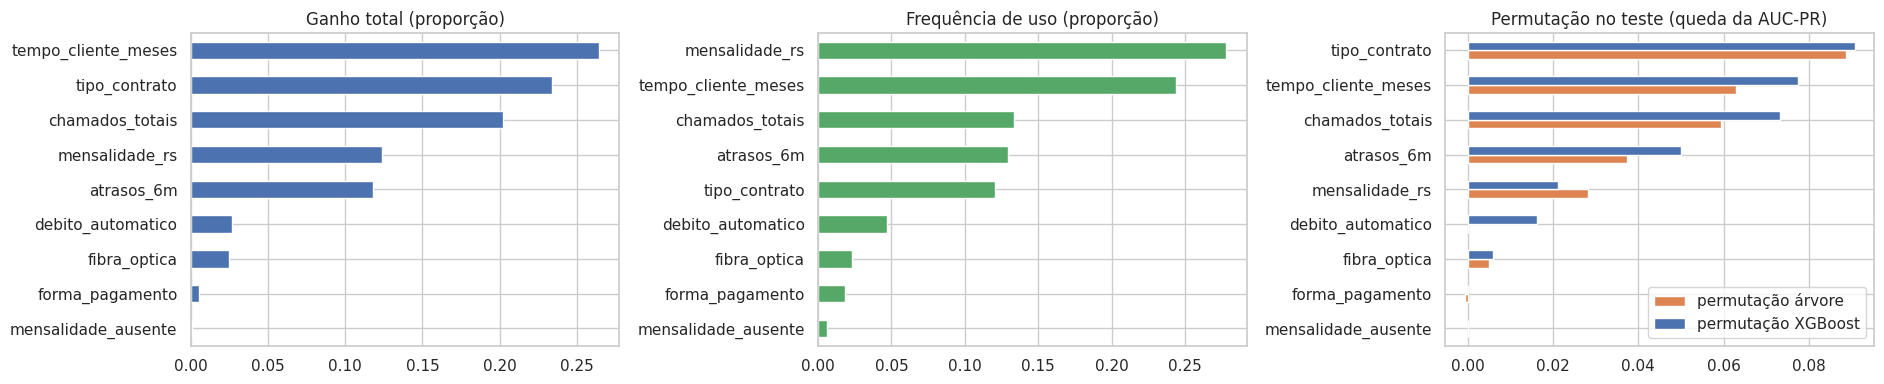

**Leitura dos resultados.** Na permutação, as três variáveis mais importantes para o XGBoost são `tipo_contrato`, `tempo_cliente_meses` e `chamados_totais`, enquanto para a árvore são `tipo_contrato`, `tempo_cliente_meses` e `chamados_totais`, isto é, os dois modelos apoiam-se no mesmo núcleo de sinais. A variável que mais se destaca na frequência de uso é `mensalidade_rs`, o que ilustra a diferença entre ser usada muitas vezes e ser decisiva. Por fim, `forma_pagamento` e `mensalidade_ausente` contribuem com praticamente nada também no XGBoost, o que reforça a recomendação de testar a sua remoção.

In [13]:
prep_final, modelo_final = xgb_final["prep"], xgb_final["modelo"]
booster = modelo_final.get_booster()
nomes = prep_final.colunas_saida_
importancias = pd.DataFrame({tipo: pd.Series({n: booster.get_score(importance_type=tipo).get(n, 0.0) for n in nomes})
                             for tipo in ["total_gain", "weight"]})
importancias = importancias.groupby(variavel_de_origem).sum()             # one-hot somado na variável original
importancias = importancias / importancias.sum()          # em proporção do total

perm_xgb = permutation_importance(xgb_final, X_teste, y_teste, scoring="average_precision", n_repeats=30,
                                  random_state=config.RANDOM_STATE)
perm_arv = permutation_importance(arvore_final, X_teste, y_teste, scoring="average_precision", n_repeats=30,
                                  random_state=config.RANDOM_STATE)
importancias = importancias.join(pd.DataFrame({"permutação XGBoost": perm_xgb.importances_mean,
                                               "permutação árvore": perm_arv.importances_mean}, index=COLUNAS_ENTRADA),
                                 how="outer").fillna(0).sort_values("permutação XGBoost", ascending=False)
display(importancias.round(3))

fig, eixos = plt.subplots(1, 3, figsize=(19, 4))
importancias["total_gain"].sort_values().plot.barh(ax=eixos[0], color="C0", title="Ganho total (proporção)")
importancias["weight"].sort_values().plot.barh(ax=eixos[1], color="C2", title="Frequência de uso (proporção)")
importancias[["permutação árvore", "permutação XGBoost"]].sort_values("permutação XGBoost").plot.barh(
    ax=eixos[2], color=["C1", "C0"], title="Permutação no teste (queda da AUC-PR)")
plt.tight_layout(); plt.show()

ordem_xgb, ordem_arv = list(importancias["permutação XGBoost"].index), list(importancias["permutação árvore"].sort_values(ascending=False).index)
nulas = [v for v in importancias.index if importancias.loc[v, "permutação XGBoost"] < 0.002]
leitura(
    f"Na permutação, as três variáveis mais importantes para o XGBoost são {lista(f'`{v}`' for v in ordem_xgb[:3])}, "
    f"enquanto para a árvore são {lista(f'`{v}`' for v in ordem_arv[:3])}"
    + (", isto é, os dois modelos apoiam-se no mesmo núcleo de sinais. " if set(ordem_xgb[:3]) == set(ordem_arv[:3]) else
       ", isto é, os dois modelos compartilham parte do núcleo de sinais, mas não todo. ")
    + f"A variável que mais se destaca na frequência de uso é `{importancias['weight'].idxmax()}`, o que ilustra a diferença "
    f"entre ser usada muitas vezes e ser decisiva. "
    + (f"Por fim, {lista(f'`{v}`' for v in nulas)} {'contribui' if len(nulas) == 1 else 'contribuem'} com praticamente "
       f"nada também no XGBoost, o que reforça a recomendação de testar a sua remoção." if nulas else
       "Por fim, diferentemente da árvore, o XGBoost aproveita algum sinal de todas as variáveis.")
)

### 10.2 Valores SHAP: o efeito de cada variável, cliente a cliente

As medidas anteriores dizem **quanto** cada variável importa, mas não **em que direção** nem **para quem**. Os ***valores SHAP*** (*SHapley Additive exPlanations*) resolvem isso: para cada cliente, decompõem a previsão do modelo (em log-odds) na soma de uma contribuição de cada variável, de modo que a soma das contribuições mais um valor de base reproduz exatamente a saída do modelo. A ideia vem da teoria dos jogos (valores de Shapley): a contribuição de uma variável é a média do quanto ela altera a previsão quando é acrescentada a todas as combinações possíveis das demais.

O XGBoost calcula esses valores de forma exata e eficiente para árvores (algoritmo TreeSHAP), com `pred_contribs=True`, sem precisar de nenhuma biblioteca adicional. O gráfico da esquerda mostra a importância global (média do valor absoluto do SHAP); os demais mostram, para as numéricas, como o efeito varia com o **valor original** da variável, que recuperamos desfazendo a padronização.

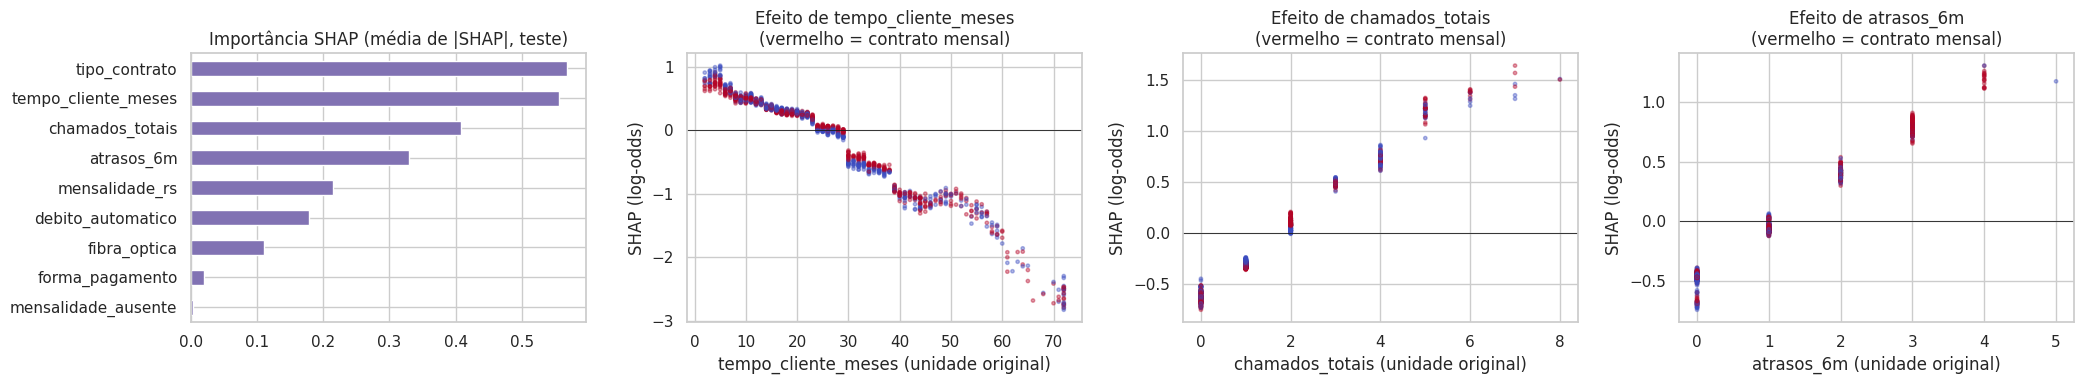

**Leitura dos resultados.** Pelos valores SHAP, as variáveis de maior efeito médio são `tipo_contrato`, `tempo_cliente_meses` e `chamados_totais`. Para `tempo_cliente_meses`, valores maiores reduzem o risco previsto (correlação de -0,98 entre o valor e o SHAP). Para `chamados_totais`, valores maiores aumentam o risco previsto (correlação de 0,99 entre o valor e o SHAP). Para `atrasos_6m`, valores maiores aumentam o risco previsto (correlação de 0,99 entre o valor e o SHAP). As cores mostram ainda que o mesmo valor de uma variável pode ter efeitos diferentes conforme o tipo de contrato: é a interação entre variáveis, que o boosting captura somando muitas árvores e que a árvore única só representava por meio de ramos separados.

In [14]:
Z_teste = prep_final.transform(X_teste)
contribuicoes = booster.predict(xgb.DMatrix(Z_teste), pred_contribs=True)       # última coluna = valor de base
shap = pd.DataFrame(contribuicoes[:, :-1], columns=nomes)
shap_variavel = shap.T.groupby(variavel_de_origem).sum().T                      # soma as colunas one-hot
importancia_shap = shap_variavel.abs().mean().sort_values()

numericas_top = [v for v in importancia_shap.index[::-1] if v in config.NUMERICAS][:3]
fig, eixos = plt.subplots(1, 1 + len(numericas_top), figsize=(6 + 5 * len(numericas_top), 4))
importancia_shap.plot.barh(ax=eixos[0], color="C4", title="Importância SHAP (média de |SHAP|, teste)")
for eixo, variavel in zip(eixos[1:], numericas_top):
    original = prep_final.para_escala_original(variavel, Z_teste[variavel])
    eixo.scatter(original, shap_variavel[variavel], s=6, alpha=0.4, c=Z_teste["tipo_contrato_Mensal"], cmap="coolwarm")
    eixo.axhline(0, c="k", lw=0.6)
    eixo.set(xlabel=variavel + " (unidade original)", ylabel="SHAP (log-odds)", title=f"Efeito de {variavel}\n(vermelho = contrato mensal)")
plt.tight_layout(); plt.show()

efeitos = []
for variavel in numericas_top:
    original = prep_final.para_escala_original(variavel, Z_teste[variavel])
    efeitos.append((variavel, np.corrcoef(original, shap_variavel[variavel])[0, 1]))
leitura(
    f"Pelos valores SHAP, as variáveis de maior efeito médio são {lista(f'`{v}`' for v in importancia_shap.index[::-1][:3])}. "
    + " ".join(f"Para `{v}`, valores maiores {'aumentam' if r > 0 else 'reduzem'} o risco previsto "
               f"(correlação de {br(r, 2)} entre o valor e o SHAP)." for v, r in efeitos)
    + " As cores mostram ainda que o mesmo valor de uma variável pode ter efeitos diferentes conforme o tipo de contrato: "
      "é a interação entre variáveis, que o boosting captura somando muitas árvores e que a árvore única só representava "
      "por meio de ramos separados."
)

## 11. Árvore de decisão × XGBoost

### 11.1 Comparação no teste

Chegamos, enfim, à comparação central do miniprojeto. A tabela reúne, para os dois modelos, as métricas de validação cruzada, as métricas de teste no ponto de operação (cada modelo com o seu limiar de 80% de recall fora da dobra) e o tempo de treinamento. Em seguida, as curvas ROC e precisão-recall dos dois modelos são sobrepostas no teste.

,árvore de decisão,XGBoost,diferença (XGB − árvore)
AUC-PR (validação),0.627,0.660,0.033
AUC-ROC (validação),0.766,0.789,0.022
recall (teste),0.760,0.798,0.038
precisão (teste),0.531,0.542,0.011
F2 (teste),0.700,0.729,0.029
acurácia (teste),0.677,0.690,0.013
% acionados (teste),0.507,0.521,0.014
AUC-ROC (teste),0.756,0.803,0.046
AUC-PR (teste),0.615,0.680,0.065
limiar,0.293,0.290,-0.003


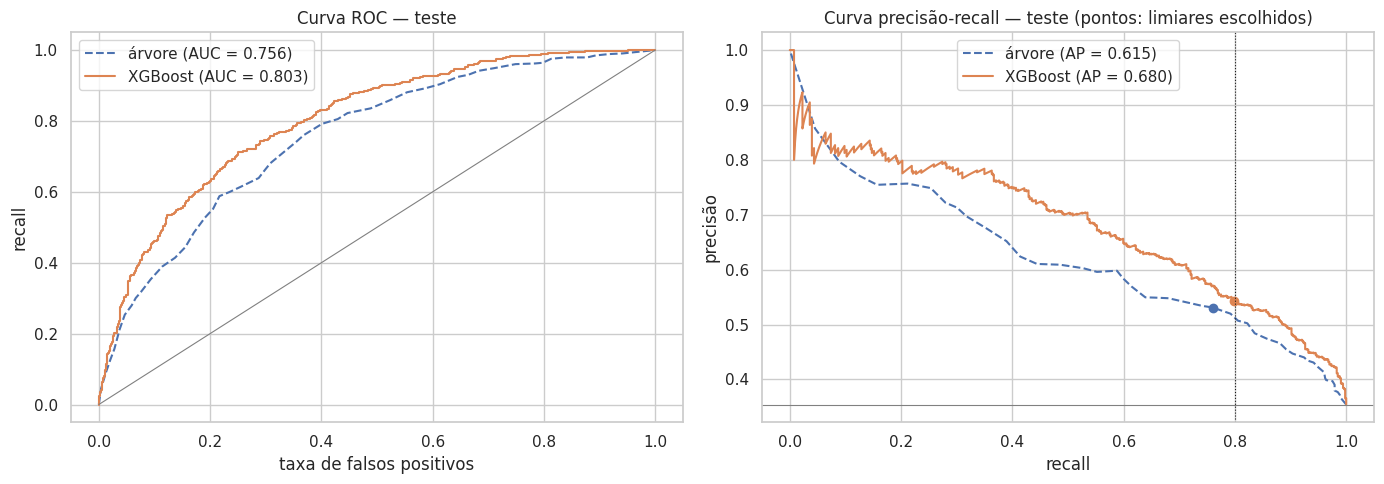

In [15]:
cv_arv = referencia.loc["árvore escolhida (Relatório 04)"]
cv_xgb = comparacao_buscas.loc[nome_xgb]
comparacao_final = pd.DataFrame({
    "árvore de decisão": {"AUC-PR (validação)": cv_arv["AUC_PR (validação)"], "AUC-ROC (validação)": cv_arv["AUC_ROC (validação)"],
                          **{f"{k} (teste)": v for k, v in m_te_arv.items()}, "limiar": limiar_arv,
                          "tempo de treino (s)": tempo_treino_arv},
    "XGBoost": {"AUC-PR (validação)": cv_xgb["AUC_PR (validação)"], "AUC-ROC (validação)": cv_xgb["AUC_ROC (validação)"],
                **{f"{k} (teste)": v for k, v in m_te.items()}, "limiar": limiar_xgb,
                "tempo de treino (s)": tempo_treino_xgb},
})
comparacao_final["diferença (XGB − árvore)"] = comparacao_final["XGBoost"] - comparacao_final["árvore de decisão"]
display(comparacao_final.round(3))

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
for nome, prob, limiar, estilo in [("árvore", prob_teste_arv, limiar_arv, "--"), ("XGBoost", prob_teste, limiar_xgb, "-")]:
    fpr, tpr, _ = roc_curve(y_teste, prob)
    eixos[0].plot(fpr, tpr, estilo, label=f"{nome} (AUC = {roc_auc_score(y_teste, prob):.3f})")
    prec, rec, _ = precision_recall_curve(y_teste, prob)
    eixos[1].plot(rec, prec, estilo, label=f"{nome} (AP = {average_precision_score(y_teste, prob):.3f})")
    m = metricas(y_teste, prob, limiar)
    eixos[1].plot(m["recall"], m["precisão"], "o", c="C0" if nome == "árvore" else "C1")
eixos[0].plot([0, 1], [0, 1], c="grey", lw=0.8)
eixos[0].set(title="Curva ROC — teste", xlabel="taxa de falsos positivos", ylabel="recall")
eixos[1].axhline(y_teste.mean(), c="grey", lw=0.8); eixos[1].axvline(config.RECALL_ALVO, c="k", ls=":", lw=0.8)
eixos[1].set(title="Curva precisão-recall — teste (pontos: limiares escolhidos)", xlabel="recall", ylabel="precisão")
eixos[0].legend(); eixos[1].legend(); plt.tight_layout(); plt.show()

### 11.2 A diferença é real? Intervalos de confiança por *bootstrap*

Com 1.493 clientes no teste, uma diferença de alguns centésimos na AUC-PR pode surgir apenas por acaso: bastaria que o teste tivesse, por sorte, alguns clientes "fáceis" a mais para um dos modelos. Para verificar se a vantagem observada é real, usamos o ***bootstrap pareado***: sorteamos, com reposição, 2.000 novas amostras de 1.493 clientes do teste e, em cada uma, calculamos a diferença entre os dois modelos **nos mesmos clientes**. O intervalo entre os percentis 2,5% e 97,5% dessas diferenças é um intervalo de confiança de 95%. Se ele não contiver o zero, a diferença é estatisticamente significativa.

In [16]:
rng = np.random.default_rng(config.RANDOM_STATE)
y_np = y_teste.to_numpy()
diferencas = {"AUC-PR": [], "AUC-ROC": [], "precisão no limiar": [], "recall no limiar": [], "% acionados no limiar": []}
for _ in range(2000):
    i = rng.integers(0, len(y_np), len(y_np))
    if y_np[i].sum() == 0:
        continue
    ma, mx = metricas(y_np[i], prob_teste_arv[i], limiar_arv), metricas(y_np[i], prob_teste[i], limiar_xgb)
    diferencas["AUC-PR"].append(mx["AUC-PR"] - ma["AUC-PR"]); diferencas["AUC-ROC"].append(mx["AUC-ROC"] - ma["AUC-ROC"])
    diferencas["precisão no limiar"].append(mx["precisão"] - ma["precisão"])
    diferencas["recall no limiar"].append(mx["recall"] - ma["recall"])
    diferencas["% acionados no limiar"].append(mx["% acionados"] - ma["% acionados"])
intervalos = pd.DataFrame({k: {"diferença média (XGB − árvore)": np.mean(v), "IC 95% inferior": np.percentile(v, 2.5),
                               "IC 95% superior": np.percentile(v, 97.5)} for k, v in diferencas.items()}).T
intervalos["significativa?"] = np.where((intervalos["IC 95% inferior"] > 0) | (intervalos["IC 95% superior"] < 0), "sim", "não")
display(intervalos.round(4))

d = intervalos.loc["AUC-PR"]
leitura(
    f"A diferença de AUC-PR no teste é de {br(abs(d['diferença média (XGB − árvore)']))} a favor "
    f"{'do XGBoost' if d['diferença média (XGB − árvore)'] > 0 else 'da árvore'}, com intervalo de confiança de 95% entre "
    f"{br(d['IC 95% inferior'])} e {br(d['IC 95% superior'])}; portanto, "
    + ("a vantagem é estatisticamente significativa. " if d["significativa?"] == "sim" else
       "**não** é possível afirmar, com 95% de confiança, que um modelo ordena os clientes melhor que o outro nesta amostra. ")
    + f"No ponto de operação, a diferença de precisão é de {br(intervalos.loc['precisão no limiar', 'diferença média (XGB − árvore)'])} "
    f"({'significativa' if intervalos.loc['precisão no limiar', 'significativa?'] == 'sim' else 'não significativa'}). "
    f"Vale lembrar que as diferenças de recall e de clientes acionados refletem também o fato de os dois limiares terem sido "
    f"calibrados fora da dobra e caírem em pontos ligeiramente diferentes da meta no teste."
)

,diferença média (XGB − árvore),IC 95% inferior,IC 95% superior,significativa?
AUC-PR,0.0652,0.0402,0.0900,sim
AUC-ROC,0.0465,0.0334,0.0606,sim
precisão no limiar,0.0114,-0.0055,0.0296,não
recall no limiar,0.0380,0.0097,0.0660,sim
% acionados no limiar,0.0142,-0.0040,0.0315,não


**Leitura dos resultados.** A diferença de AUC-PR no teste é de 0,065 a favor do XGBoost, com intervalo de confiança de 95% entre 0,040 e 0,090; portanto, a vantagem é estatisticamente significativa. No ponto de operação, a diferença de precisão é de 0,011 (não significativa). Vale lembrar que as diferenças de recall e de clientes acionados refletem também o fato de os dois limiares terem sido calibrados fora da dobra e caírem em pontos ligeiramente diferentes da meta no teste.

### 11.3 Desempenho, interpretabilidade e custo

A escolha entre os dois modelos não depende só da métrica. A tabela abaixo resume os critérios que pesam em uma decisão real de negócio; os valores das linhas de desempenho e de tempo vêm das células anteriores.

In [17]:
resumo = pd.DataFrame({
    "árvore de decisão": [br(m_te_arv["AUC-PR"]), pct(m_te_arv["precisão"]), pct(m_te_arv["% acionados"]),
                          f"{br(tempo_treino_arv, 2)} s", "total: regras SE-ENTÃO legíveis por qualquer pessoa",
                          "degraus (uma por folha)", "simples: regras podem virar SQL ou planilha"],
    "XGBoost": [br(m_te["AUC-PR"]), pct(m_te["precisão"]), pct(m_te["% acionados"]), f"{br(tempo_treino_xgb, 2)} s",
                "parcial: importâncias e SHAP por cliente", "contínuas (ajuste fino do recall)",
                "requer a biblioteca e o modelo serializado"],
}, index=["AUC-PR (teste)", "precisão no limiar (teste)", "% acionados (teste)", "tempo de treino",
          "interpretabilidade", "probabilidades", "implantação"])
display(resumo)

,árvore de decisão,XGBoost
AUC-PR (teste),"0,615","0,680"
precisão no limiar (teste),"53,1%","54,2%"
% acionados (teste),"50,7%","52,1%"
tempo de treino,"0,03 s","0,25 s"
interpretabilidade,total: regras SE-ENTÃO legíveis por qualquer p...,parcial: importâncias e SHAP por cliente
probabilidades,degraus (uma por folha),contínuas (ajuste fino do recall)
implantação,simples: regras podem virar SQL ou planilha,requer a biblioteca e o modelo serializado


## 12. Exportação dos resultados

Salvamos os hiperparâmetros, o limiar e as métricas do XGBoost escolhido em `resultados/xgboost_escolhido.json`, no mesmo formato usado para a árvore, junto com o resumo da comparação. Assim, os resultados das duas partes do MP2 ficam registrados de forma reprodutível para a apresentação e para o MP3.

In [18]:
def para_json(v):
    return v.item() if hasattr(v, "item") else v

resultado = {
    "modelo": "XGBClassifier",
    "busca": nome_xgb,
    "hiperparametros": {k: para_json(v) for k, v in hp_xgb.items()},
    "random_state": config.RANDOM_STATE,
    "limiar": limiar_xgb,
    "recall_alvo": config.RECALL_ALVO,
    "validacao_cruzada": {k: para_json(v) for k, v in comparacao_buscas.loc[nome_xgb].items() if "(validação)" in k},
    "teste": {k: para_json(v) for k, v in m_te.items()},
    "comparacao_com_arvore_bootstrap": {k: {c: para_json(v) for c, v in linha.items()}
                                        for k, linha in intervalos.to_dict(orient="index").items()},
    "buscas": {"grid": {"tempo_s": tempo_grade, "melhor_auc_pr": para_json(resultados_grade["mean_test_AUC_PR"].max())},
               "optuna": {"tempo_s": tempo_optuna, "tentativas": len(tentativas), "interrompidas": n_podadas,
                          "melhor_auc_pr": estudo.best_value}},
}
config.RESULTADOS.mkdir(parents=True, exist_ok=True)
with open(config.XGBOOST_ESCOLHIDO, "w", encoding="utf-8") as arquivo:
    json.dump(resultado, arquivo, ensure_ascii=False, indent=2)
print(f"Salvo em {config.XGBOOST_ESCOLHIDO.relative_to(config.RAIZ)}")

Salvo em resultados/xgboost_escolhido.json


## 13. Conclusão

Este relatório aplicou ao XGBoost o mesmo protocolo usado para a árvore de decisão e, com isso, permite uma comparação justa entre os dois modelos. A célula abaixo resume os resultados obtidos nesta execução; em seguida, discutimos o que eles significam para o projeto.

In [19]:
ganho_ap = m_te["AUC-PR"] - m_te_arv["AUC-PR"]
significativo = intervalos.loc["AUC-PR", "significativa?"] == "sim"
leitura(
    f"O XGBoost escolhido ({nome_xgb.split('— ')[1]}; {hp_xgb['n_estimators']} árvores, profundidade até "
    f"{hp_xgb['max_depth']}, taxa {num(hp_xgb['learning_rate'])}) alcançou AUC-PR de {br(cv_xgb['AUC_PR (validação)'])} na "
    f"validação cruzada e de {br(m_te['AUC-PR'])} no teste, contra {br(cv_arv['AUC_PR (validação)'])} e {br(m_te_arv['AUC-PR'])} da "
    f"árvore. No ponto de operação de 80% de recall, o XGBoost atingiu {pct(m_te['recall'])} de recall no teste, com precisão de "
    f"{pct(m_te['precisão'])} e {pct(m_te['% acionados'])} da base acionada; a árvore, {pct(m_te_arv['recall'])}, "
    f"{pct(m_te_arv['precisão'])} e {pct(m_te_arv['% acionados'])}. "
    + (f"A vantagem de {br(ganho_ap)} na AUC-PR é estatisticamente significativa pelo bootstrap, de modo que o ensemble "
       f"de fato ordena melhor os clientes por risco." if significativo and ganho_ap > 0 else
       f"A diferença de {br(ganho_ap)} na AUC-PR, contudo, não é estatisticamente significativa pelo bootstrap; em outras palavras, "
       f"nesta base, o ganho do ensemble sobre uma árvore bem podada é pequeno demais para ser distinguido do acaso."),
    titulo="Síntese desta execução."
)

**Síntese desta execução.** O XGBoost escolhido (GridSearchCV; 500 árvores, profundidade até 2, taxa 0,03) alcançou AUC-PR de 0,660 na validação cruzada e de 0,680 no teste, contra 0,627 e 0,615 da árvore. No ponto de operação de 80% de recall, o XGBoost atingiu 79,8% de recall no teste, com precisão de 54,2% e 52,1% da base acionada; a árvore, 76,0%, 53,1% e 50,7%. A vantagem de 0,065 na AUC-PR é estatisticamente significativa pelo bootstrap, de modo que o ensemble de fato ordena melhor os clientes por risco.

Independentemente dos números exatos, o percurso dos dois relatórios permite tirar algumas conclusões gerais:

1. **O controle de complexidade é o que mais importa nesta base.** Tanto na árvore quanto no XGBoost, os maiores ganhos vieram de impedir que o modelo decorasse o treino: o tamanho mínimo das folhas na árvore e a combinação de profundidade, taxa de aprendizado e regularização no boosting. Os hiperparâmetros padrão do XGBoost, pensados para bases grandes, não são adequados para 3.483 clientes.
2. **O número de árvores e a taxa de aprendizado precisam ser ajustados juntos.** A Seção 4 mostrou que taxas menores deslocam o ponto ótimo para mais árvores e tornam o modelo menos sensível a esse número, ao custo de mais tempo de treino.
3. **O Optuna explora espaços maiores com um custo controlado**, graças à busca adaptativa e ao pruner. A sua vantagem sobre uma grade bem informada, porém, depende do tamanho do problema e deve ser medida, e não presumida.
4. **Os dois modelos concordam sobre o que causa o churn:** tipo de contrato, tempo de casa e chamados lideram em todas as medidas de importância, e os valores SHAP confirmam a direção dos efeitos encontrada nas regras da árvore. Essa convergência entre um modelo transparente e um modelo de caixa-preta aumenta a confiança nos achados.
5. **A escolha final é uma decisão de negócio.** Se o ganho do XGBoost for significativo, ele reduz o número de clientes acionados para a mesma meta de recall e, portanto, o custo das campanhas. Se não for, a árvore entrega praticamente o mesmo resultado com regras que a equipe de retenção pode ler, auditar e implantar diretamente. Em ambos os casos, as regras SE-ENTÃO da árvore continuam úteis para **explicar** a estratégia, mesmo que o XGBoost seja o modelo usado para **priorizar** os clientes.

Como próximos passos, os resultados sugerem testar a remoção das variáveis sem contribuição (forma de pagamento e indicador de ausência da mensalidade), recalibrar o limiar periodicamente em produção e, no MP3, verificar se os agrupamentos não supervisionados encontram os mesmos perfis de risco que as regras da árvore descreveram.

---
### Anexo — baixar o arquivo gerado (Colab)

Depois, suba-o em `resultados/` pelo GitHub (*Add file → Upload files*).

In [20]:
# Só executa no Colab: baixa o resultado do XGBoost para o computador.
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(str(config.XGBOOST_ESCOLHIDO))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>